# Stage 1 — RGB Camera Perception Baseline
## Seeing Through Fog dataset

Este notebook parte del dataset RGB **ya descargado y extraído**. No instala paquetes, no descarga datos y no vuelve a extraer archivos.

### Objetivos
- Cargar las imágenes RGB existentes.
- Calcular indicadores de brillo, contraste y nitidez.
- Generar estadísticas, histogramas y muestras representativas.
- Permitir inferencia YOLO opcional con pesos locales ya disponibles.

### Requisitos
El entorno virtual del proyecto debe tener disponibles `numpy`, `pandas`, `matplotlib` y `opencv-python`. La inferencia YOLO requiere además `ultralytics` y un archivo de pesos local.

**Nota metodológica:** brillo, contraste y varianza del Laplaciano son indicadores básicos; no son medidas definitivas de calidad perceptual. Precision, Recall, F1 y mAP requieren Ground Truth válido y asociación correcta entre predicciones y anotaciones.

In [1]:
# 0. Import required libraries
# These packages are already available in the project virtual environment.

from pathlib import Path
import sys
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. PROJECT CONFIGURATION

In [2]:
# =============================================================================

PROJECT_ROOT = Path("/home/maritza/projects/autonomous_vehicle")
DATASET_ROOT = PROJECT_ROOT / "dataset" / "seeing_through_fog"
RGB_DIR = DATASET_ROOT / "extracted" / "cam_stereo_left_lut"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "stage1_rgb_baseline"
PLOTS_DIR = OUTPUT_DIR / "plots"
SAMPLES_DIR = OUTPUT_DIR / "samples"

# Optional: point this to an existing local YOLO .pt weights file.
# Leave as None to run the image-quality baseline only.
YOLO_WEIGHTS = None
# Example:
# YOLO_WEIGHTS = PROJECT_ROOT / "models" / "yolo_model.pt"

# None processes all images. Use an integer for a quick test.
MAX_IMAGES = None

YOLO_SAMPLE_COUNT = 12
YOLO_CONFIDENCE = 0.25
YOLO_IMAGE_SIZE = 640

SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


# =============================================================================

## 2. VALIDATE DATASET AND PREPARE OUTPUT DIRECTORIES

In [3]:
# =============================================================================

def prepare_directories():
    """Create output folders without modifying the source dataset."""
    if not RGB_DIR.is_dir():
        raise FileNotFoundError(
            f"RGB dataset directory not found: {RGB_DIR}\n"
            "Verify that the dataset has already been extracted."
        )

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    PLOTS_DIR.mkdir(parents=True, exist_ok=True)
    SAMPLES_DIR.mkdir(parents=True, exist_ok=True)


def discover_images():
    """Discover supported image files in the existing RGB directory."""
    paths = sorted(
        p for p in RGB_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    )

    if MAX_IMAGES is not None:
        paths = paths[:MAX_IMAGES]

    if not paths:
        raise RuntimeError(f"No supported images found in {RGB_DIR}")

    return paths


# =============================================================================

## 3. IMAGE QUALITY METRICS

In [4]:
# =============================================================================

def calculate_image_metrics(image_bgr):
    """
    Calculate basic image-quality indicators.

    Brightness: mean grayscale intensity.
    Contrast: standard deviation of grayscale intensity.
    Sharpness: variance of the Laplacian.

    These are useful indicators, not definitive perceptual-quality scores.
    Their values are also influenced by scene content.
    """
    if image_bgr is None:
        raise ValueError("Image could not be decoded.")

    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    height, width = gray.shape

    return {
        "width": int(width),
        "height": int(height),
        "channels": int(image_bgr.shape[2]) if image_bgr.ndim == 3 else 1,
        "dtype": str(image_bgr.dtype),
        "brightness_mean": float(np.mean(gray)),
        "contrast_std": float(np.std(gray)),
        "sharpness_laplacian_var": float(
            cv2.Laplacian(gray, cv2.CV_64F).var()
        ),
        "pixel_min": int(gray.min()),
        "pixel_max": int(gray.max()),
    }


def analyze_dataset(image_paths):
    """Calculate quality indicators for every readable image."""
    records = []
    failed_files = []
    start_time = time.time()
    total = len(image_paths)

    print("\nIMAGE QUALITY ANALYSIS")
    print("=" * 72)

    for index, image_path in enumerate(image_paths, start=1):
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

        if image is None:
            failed_files.append(str(image_path))
            continue

        try:
            metrics = calculate_image_metrics(image)
            metrics["image_name"] = image_path.name
            metrics["image_path"] = str(image_path)
            records.append(metrics)
        except Exception as exc:
            failed_files.append(f"{image_path} | {exc}")

        if index % 250 == 0 or index == total:
            print(f"Processed {index:,}/{total:,} images")

    elapsed = time.time() - start_time

    if not records:
        raise RuntimeError("No images could be successfully analyzed.")

    df = pd.DataFrame(records)
    columns = [
        "image_name", "image_path", "width", "height", "channels", "dtype",
        "brightness_mean", "contrast_std", "sharpness_laplacian_var",
        "pixel_min", "pixel_max",
    ]
    df = df[columns]

    csv_path = OUTPUT_DIR / "rgb_image_quality_metrics.csv"
    df.to_csv(csv_path, index=False)

    print("\nANALYSIS SUMMARY")
    print("-" * 72)
    print(f"Images discovered:       {total:,}")
    print(f"Images analyzed:         {len(df):,}")
    print(f"Images that failed:      {len(failed_files):,}")
    print(f"Processing time:         {elapsed:.1f} seconds")
    print(f"Metrics CSV:             {csv_path}")

    if failed_files:
        failed_path = OUTPUT_DIR / "failed_images.txt"
        failed_path.write_text("\n".join(failed_files), encoding="utf-8")
        print(f"Failed-file log:         {failed_path}")

    return df


# =============================================================================

## 4. DATASET-LEVEL SUMMARY

In [5]:
# =============================================================================

def summarize_metrics(df):
    """Save descriptive statistics and report image dimensions."""
    metric_columns = [
        "brightness_mean",
        "contrast_std",
        "sharpness_laplacian_var",
    ]

    summary = df[metric_columns].describe().T
    summary_path = OUTPUT_DIR / "rgb_quality_summary.csv"
    summary.to_csv(summary_path)

    print("\nQUALITY METRIC SUMMARY")
    print("=" * 72)
    print(summary.round(3).to_string())
    print(f"\nSummary saved to: {summary_path}")

    dimensions = (
        df.groupby(["width", "height"])
        .size()
        .reset_index(name="image_count")
        .sort_values("image_count", ascending=False)
    )

    print("\nIMAGE DIMENSIONS")
    print("-" * 72)
    print(dimensions.to_string(index=False))


# =============================================================================

## 5. QUALITY-DISTRIBUTION PLOTS

In [6]:
# =============================================================================

def save_quality_plots(df):
    """Save a histogram for each image-quality indicator."""
    plot_specs = [
        ("brightness_mean", "Mean grayscale intensity",
         "Brightness distribution"),
        ("contrast_std", "Grayscale standard deviation",
         "Global contrast distribution"),
        ("sharpness_laplacian_var", "Variance of Laplacian",
         "Sharpness-indicator distribution"),
    ]

    for column, xlabel, title in plot_specs:
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.hist(df[column].dropna(), bins=50)
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Number of images")
        ax.grid(True, alpha=0.25)
        fig.tight_layout()

        fig.savefig(PLOTS_DIR / f"{column}_distribution.png", dpi=150)
        plt.close(fig)

    print(f"\nQuality plots saved in: {PLOTS_DIR}")


# =============================================================================

## 6. REPRESENTATIVE IMAGE SAMPLES

In [7]:
# =============================================================================

def save_representative_samples(df, count=6):
    """
    Save a contact sheet using low, median and high metric values.
    These are statistical samples, not weather-condition labels.
    """
    candidates = []

    for metric, label in [
        ("brightness_mean", "Brightness"),
        ("contrast_std", "Contrast"),
        ("sharpness_laplacian_var", "Sharpness"),
    ]:
        valid = df.dropna(subset=[metric]).sort_values(metric)
        if valid.empty:
            continue

        positions = [0, len(valid) // 2, len(valid) - 1]
        levels = ["Low", "Median", "High"]

        for position, level in zip(positions, levels):
            row = valid.iloc[position]
            candidates.append((row["image_path"], f"{label} — {level}"))

    unique = []
    seen = set()
    for path, label in candidates:
        if path not in seen:
            unique.append((path, label))
            seen.add(path)

    unique = unique[:count]
    if not unique:
        return

    columns = 3
    rows = int(np.ceil(len(unique) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (path, label) in zip(axes, unique):
        image = cv2.imread(path, cv2.IMREAD_COLOR)
        if image is None:
            continue

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image_rgb)
        ax.set_title(label)
        ax.axis("off")

    fig.tight_layout()
    output_path = SAMPLES_DIR / "representative_rgb_samples.png"
    fig.savefig(output_path, dpi=140)
    plt.close(fig)

    print(f"Representative samples saved to: {output_path}")


# =============================================================================

## 7. OPTIONAL YOLO INFERENCE — LOCAL MODEL ONLY

In [8]:
# =============================================================================

def run_optional_yolo(image_paths):
    """
    Run YOLO only if Ultralytics is already installed and local weights
    are configured. This function does not download model weights.
    """
    if YOLO_WEIGHTS is None:
        print("\nYOLO INFERENCE SKIPPED")
        print("-" * 72)
        print("YOLO_WEIGHTS is None. Image-quality analysis is complete.")
        print(
            "Configure YOLO_WEIGHTS with an existing local .pt file "
            "to enable inference."
        )
        return

    weights_path = Path(YOLO_WEIGHTS)
    if not weights_path.is_file():
        print(f"\nYOLO inference skipped: model not found: {weights_path}")
        return

    try:
        from ultralytics import YOLO
    except ImportError:
        print("\nYOLO inference skipped: ultralytics is not available.")
        print("No package installation was attempted.")
        return

    print("\nYOLO INFERENCE")
    print("=" * 72)
    print(f"Local model: {weights_path}")

    model = YOLO(str(weights_path))
    sample_paths = image_paths[:YOLO_SAMPLE_COUNT]
    inference_records = []

    for image_path in sample_paths:
        results = model.predict(
            source=str(image_path),
            conf=YOLO_CONFIDENCE,
            imgsz=YOLO_IMAGE_SIZE,
            verbose=False,
        )

        result = results[0]
        boxes = result.boxes
        detection_count = 0 if boxes is None else len(boxes)

        inference_records.append({
            "image_name": image_path.name,
            "detection_count": detection_count,
        })

        annotated = result.plot()
        annotated_path = SAMPLES_DIR / f"yolo_{image_path.stem}.jpg"
        cv2.imwrite(str(annotated_path), annotated)

        print(f"{image_path.name}: {detection_count} detections")

    inference_df = pd.DataFrame(inference_records)
    inference_csv = OUTPUT_DIR / "yolo_sample_inference.csv"
    inference_df.to_csv(inference_csv, index=False)

    print(f"\nYOLO sample results saved to: {inference_csv}")
    print(f"Annotated images saved in: {SAMPLES_DIR}")
    print(
        "Detections alone do not provide Precision, Recall, F1 or mAP. "
        "Those require valid ground-truth annotations and matching."
    )


# =============================================================================

## 8. Execute the complete Stage 1 analysis

Ejecuta esta última celda después de las secciones anteriores. El análisis procesa todas las imágenes salvo que `MAX_IMAGES` se configure con un límite.

In [9]:
# =============================================================================

def main():
    print("STAGE 1 — RGB CAMERA PERCEPTION BASELINE")
    print("=" * 72)
    print("Using the existing extracted dataset.")
    print("No installation, download, or archive extraction will be performed.")

    prepare_directories()
    image_paths = discover_images()

    print(f"\nRGB directory: {RGB_DIR}")
    print(f"Images discovered: {len(image_paths):,}")
    print(f"Output directory: {OUTPUT_DIR}")

    df = analyze_dataset(image_paths)
    summarize_metrics(df)
    save_quality_plots(df)
    save_representative_samples(df)
    run_optional_yolo(image_paths)

    print("\nSTAGE 1 RGB ANALYSIS FINISHED")
    print("=" * 72)
    print(f"All outputs are in: {OUTPUT_DIR}")


if __name__ == "__main__":
    try:
        main()
    except Exception as error:
        print("\nSTAGE 1 EXECUTION FAILED")
        print("=" * 72)
        print(f"{type(error).__name__}: {error}")
        sys.exit(1)

STAGE 1 — RGB CAMERA PERCEPTION BASELINE
Using the existing extracted dataset.
No installation, download, or archive extraction will be performed.

RGB directory: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/cam_stereo_left_lut
Images discovered: 12,997
Output directory: /home/maritza/projects/autonomous_vehicle/outputs/stage1_rgb_baseline

IMAGE QUALITY ANALYSIS
Processed 250/12,997 images
Processed 500/12,997 images
Processed 750/12,997 images
Processed 1,000/12,997 images
Processed 1,250/12,997 images
Processed 1,500/12,997 images
Processed 1,750/12,997 images
Processed 2,000/12,997 images
Processed 2,250/12,997 images
Processed 2,500/12,997 images
Processed 2,750/12,997 images
Processed 3,000/12,997 images
Processed 3,250/12,997 images
Processed 3,500/12,997 images
Processed 3,750/12,997 images
Processed 4,000/12,997 images
Processed 4,250/12,997 images
Processed 4,500/12,997 images
Processed 4,750/12,997 images
Processed 5,000/12,997 images
Proces

RGB QUALITY VISUALIZATION
Images available: 12,997


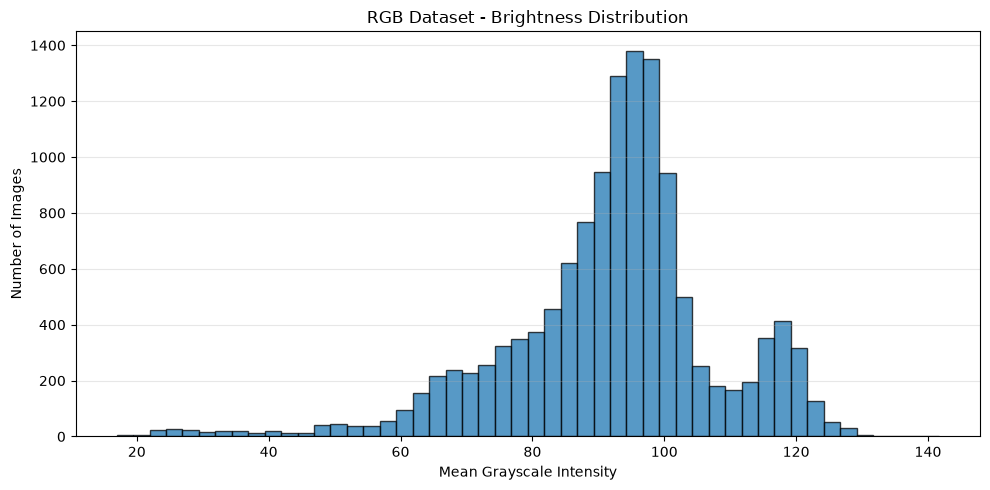

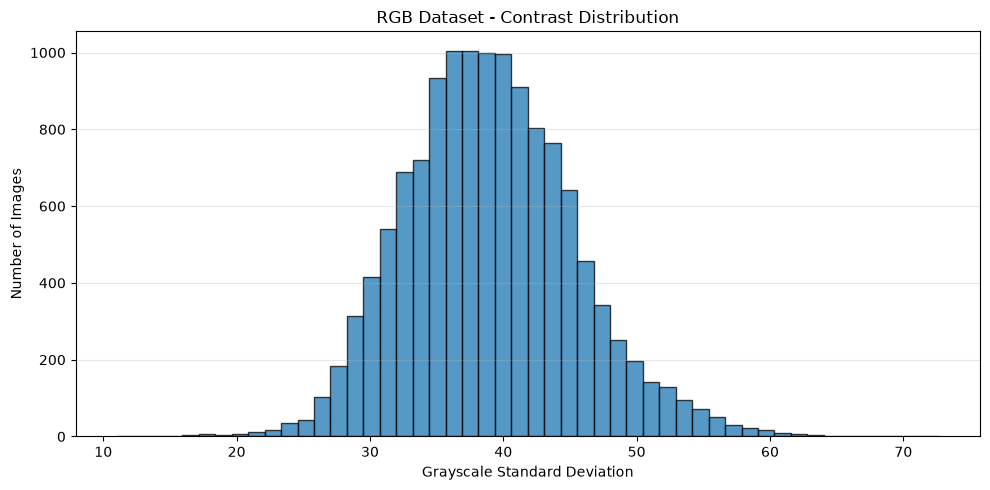

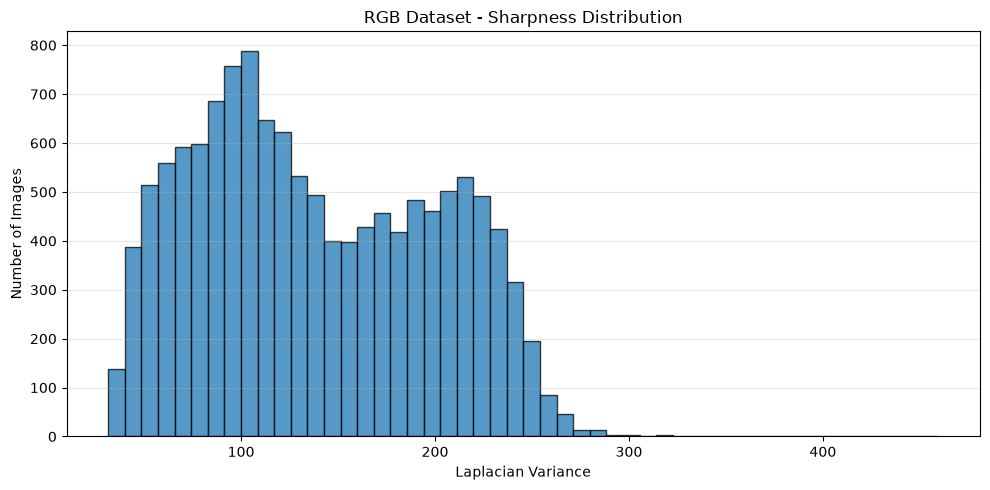

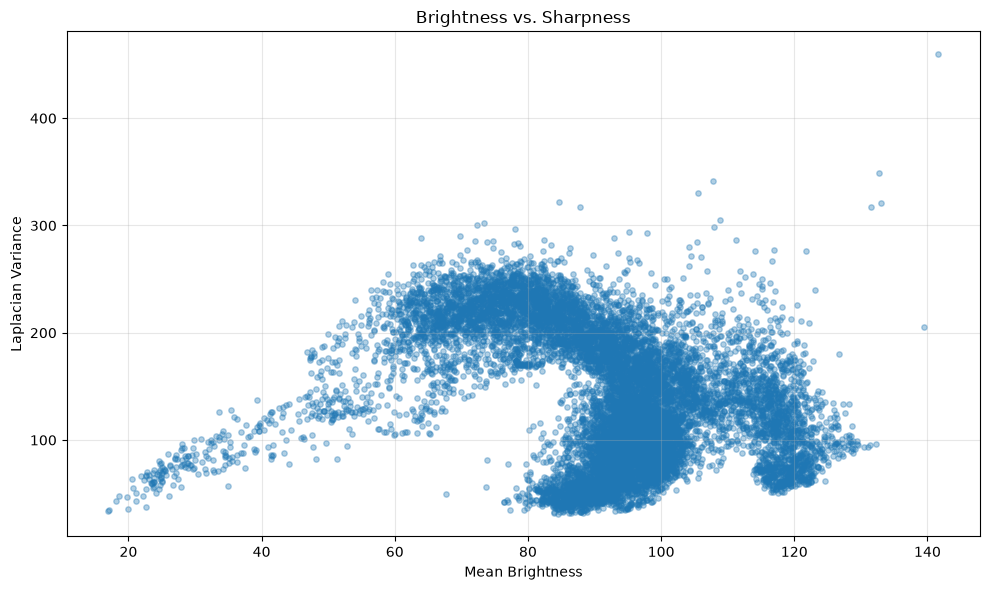


VISUALIZATION COMPLETED
Generated plots: 4
Output directory: /home/maritza/projects/autonomous_vehicle/outputs/stage1_rgb_baseline/plots


In [11]:
# 2.5 Advanced RGB Quality Visualization

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Load previously calculated image metrics
# --------------------------------------------------

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "stage1_rgb_baseline"

PLOTS_DIR = OUTPUT_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

metrics_path = OUTPUT_DIR / "rgb_image_quality_metrics.csv"

df = pd.read_csv(metrics_path)

print("RGB QUALITY VISUALIZATION")
print("=" * 60)
print(f"Images available: {len(df):,}")


# --------------------------------------------------
# 2. Brightness distribution
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    df["brightness_mean"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.title("RGB Dataset - Brightness Distribution")
plt.xlabel("Mean Grayscale Intensity")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "brightness_distribution.png", dpi=150)
plt.show()


# --------------------------------------------------
# 3. Contrast distribution
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    df["contrast_std"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.title("RGB Dataset - Contrast Distribution")
plt.xlabel("Grayscale Standard Deviation")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "contrast_distribution.png", dpi=150)
plt.show()


# --------------------------------------------------
# 4. Sharpness distribution
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    df["sharpness_laplacian_var"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.title("RGB Dataset - Sharpness Distribution")
plt.xlabel("Laplacian Variance")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "sharpness_distribution.png", dpi=150)
plt.show()


# --------------------------------------------------
# 5. Brightness vs. Sharpness
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    df["brightness_mean"],
    df["sharpness_laplacian_var"],
    alpha=0.35,
    s=15
)

plt.title("Brightness vs. Sharpness")
plt.xlabel("Mean Brightness")
plt.ylabel("Laplacian Variance")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "brightness_vs_sharpness.png", dpi=150)
plt.show()


# --------------------------------------------------
# 6. Save visualization summary
# --------------------------------------------------

print("\nVISUALIZATION COMPLETED")
print("=" * 60)
print(f"Generated plots: 4")
print(f"Output directory: {PLOTS_DIR}")

In [22]:
# 2.6 Prepare Image Metadata for Category Analysis

import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. Load existing image quality metrics
# --------------------------------------------------

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "stage1_rgb_baseline"

metrics_path = OUTPUT_DIR / "rgb_image_quality_metrics.csv"

df = pd.read_csv(metrics_path)

# --------------------------------------------------
# 2. Extract timestamp from image filenames
# --------------------------------------------------

# Expected format:
# YYYY-MM-DD_HH-MM-SS_FRAME.png

timestamp_pattern = r"(\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})"

df["timestamp"] = df["image_name"].str.extract(
    timestamp_pattern
)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    format="%Y-%m-%d_%H-%M-%S",
    errors="coerce"
)

# --------------------------------------------------
# 3. Extract date and time components
# --------------------------------------------------

df["date"] = df["timestamp"].dt.date
df["hour"] = df["timestamp"].dt.hour

# --------------------------------------------------
# 4. Inspect timestamp extraction
# --------------------------------------------------

print("IMAGE METADATA PREPARATION")
print("=" * 60)

print(f"Total images: {len(df):,}")
print(f"Valid timestamps: {df['timestamp'].notna().sum():,}")
print(f"Missing timestamps: {df['timestamp'].isna().sum():,}")

print("\nFIRST RECORDS")
print("-" * 60)

display(
    df[
        ["image_name", "timestamp", "date", "hour"]
    ].head(10)
)

# --------------------------------------------------
# 5. Save enriched dataset
# --------------------------------------------------

metadata_output = OUTPUT_DIR / "rgb_image_quality_with_timestamps.csv"

df.to_csv(metadata_output, index=False)

print(f"\nSaved metadata: {metadata_output}")

# 2.7 Inspect Weather Station Metadata

from pathlib import Path
import json

# --------------------------------------------------
# 1. Define metadata directory
# --------------------------------------------------

DOWNLOAD_DIR = PROJECT_ROOT / "dataset" / "seeing_through_fog" / "downloads"

# --------------------------------------------------
# 2. Locate weather station resources
# --------------------------------------------------

# Inspect the original download metadata
metadata_path = PROJECT_ROOT / "download_links.json"

with open(metadata_path, "r", encoding="utf-8") as file:
    dataset_info = json.load(file)

urls = dataset_info["urls"]

weather_entries = [
    item for item in urls
    if "weather_station" in item["key"].lower()
]

print("WEATHER STATION RESOURCES")
print("=" * 60)
print(f"Number of matching resources: {len(weather_entries)}")

for item in weather_entries:
    print(f"Key: {item['key']}")

# 2.7 Check Weather Station Archive

from pathlib import Path

# --------------------------------------------------
# 1. Define weather station paths
# --------------------------------------------------

DOWNLOAD_DIR = PROJECT_ROOT / "dataset" / "seeing_through_fog" / "downloads"

WEATHER_DIR = DOWNLOAD_DIR / "weather_station"

WEATHER_ARCHIVE = WEATHER_DIR / "weather_station.zip"

# --------------------------------------------------
# 2. Check archive availability
# --------------------------------------------------

print("WEATHER STATION ARCHIVE CHECK")
print("=" * 60)

if WEATHER_ARCHIVE.exists():

    archive_size = WEATHER_ARCHIVE.stat().st_size / (1024**2)

    print("Archive found.")
    print(f"File: {WEATHER_ARCHIVE}")
    print(f"Size: {archive_size:.2f} MB")

else:

    print("Weather station archive not found.")
    print(f"Expected location: {WEATHER_ARCHIVE}")

# 2.8 Inspect Weather Station Download Metadata

weather_key = "SeeingThroughFog/weather_station/weather_station.zip"

weather_entry = next(
    (item for item in dataset_info["urls"] if item["key"] == weather_key),
    None
)

print("WEATHER STATION DOWNLOAD METADATA")
print("=" * 60)

if weather_entry is not None:
    print("Resource found in metadata.")
    print(f"Key: {weather_entry['key']}")
    print(f"URL available: {bool(weather_entry.get('url'))}")
else:
    print("Resource not found in download metadata.")

# 2.9 Download Weather Station Archive

import requests
from pathlib import Path

WEATHER_DIR = DOWNLOAD_DIR / "weather_station"
WEATHER_DIR.mkdir(parents=True, exist_ok=True)

WEATHER_ARCHIVE = WEATHER_DIR / "weather_station.zip"
weather_url = weather_entry["url"]

print("WEATHER STATION DOWNLOAD")
print("=" * 60)

response = requests.get(weather_url, stream=True, timeout=60)
response.raise_for_status()

total_bytes = 0

with open(WEATHER_ARCHIVE, "wb") as file:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            file.write(chunk)
            total_bytes += len(chunk)

print("Download completed.")
print(f"File: {WEATHER_ARCHIVE.name}")
print(f"Size: {total_bytes / (1024**2):.2f} MB")
print(f"Saved successfully: {WEATHER_ARCHIVE.exists()}")

# 2.10 Check Weather Station Archive Integrity

import zipfile

print("WEATHER STATION ARCHIVE INTEGRITY")
print("=" * 60)

if zipfile.is_zipfile(WEATHER_ARCHIVE):
    with zipfile.ZipFile(WEATHER_ARCHIVE, "r") as archive:
        bad_file = archive.testzip()

        if bad_file is None:
            print("ZIP integrity check passed.")
            print("No corrupted files detected.")
        else:
            print(f"Corrupted file detected: {bad_file}")
else:
    print("Invalid ZIP archive.")

# 2.11 Extract Weather Station Dataset

WEATHER_EXTRACTED_DIR = (
    PROJECT_ROOT
    / "dataset"
    / "seeing_through_fog"
    / "extracted"
    / "weather_station"
)

WEATHER_EXTRACTED_DIR.mkdir(parents=True, exist_ok=True)

print("WEATHER STATION EXTRACTION")
print("=" * 60)

with zipfile.ZipFile(WEATHER_ARCHIVE, "r") as archive:
    archive.extractall(WEATHER_EXTRACTED_DIR)

print("Extraction completed.")
print(f"Extracted to: {WEATHER_EXTRACTED_DIR}")

IMAGE METADATA PREPARATION
Total images: 12,997
Valid timestamps: 12,997
Missing timestamps: 0

FIRST RECORDS
------------------------------------------------------------


,image_name,timestamp,date,hour
0,2018-02-03_20-48-35_00400.png,2018-02-03 20:48:35,2018-02-03,20
1,2018-02-03_20-48-35_00500.png,2018-02-03 20:48:35,2018-02-03,20
2,2018-02-03_20-49-38_00000.png,2018-02-03 20:49:38,2018-02-03,20
3,2018-02-03_20-49-38_00100.png,2018-02-03 20:49:38,2018-02-03,20
4,2018-02-03_20-49-38_00200.png,2018-02-03 20:49:38,2018-02-03,20
5,2018-02-03_20-50-46_00000.png,2018-02-03 20:50:46,2018-02-03,20
6,2018-02-03_20-50-46_00100.png,2018-02-03 20:50:46,2018-02-03,20
7,2018-02-03_20-50-46_00200.png,2018-02-03 20:50:46,2018-02-03,20
8,2018-02-03_20-52-49_00000.png,2018-02-03 20:52:49,2018-02-03,20
9,2018-02-03_20-53-15_00000.png,2018-02-03 20:53:15,2018-02-03,20



Saved metadata: /home/maritza/projects/autonomous_vehicle/outputs/stage1_rgb_baseline/rgb_image_quality_with_timestamps.csv
WEATHER STATION RESOURCES
Number of matching resources: 1
Key: SeeingThroughFog/weather_station/weather_station.zip
WEATHER STATION ARCHIVE CHECK
Archive found.
File: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/downloads/weather_station/weather_station.zip
Size: 6.38 MB
WEATHER STATION DOWNLOAD METADATA
Resource found in metadata.
Key: SeeingThroughFog/weather_station/weather_station.zip
URL available: True
WEATHER STATION DOWNLOAD
Download completed.
File: weather_station.zip
Size: 6.38 MB
Saved successfully: True
WEATHER STATION ARCHIVE INTEGRITY
ZIP integrity check passed.
No corrupted files detected.
WEATHER STATION EXTRACTION
Extraction completed.
Extracted to: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/weather_station


In [26]:
# 2.12 Inspect Extracted Weather Station Files

from pathlib import Path

weather_files = sorted(
    path for path in WEATHER_EXTRACTED_DIR.rglob("*")
    if path.is_file()
)

print("WEATHER STATION FILE INVENTORY")
print("=" * 60)
print(f"Total files: {len(weather_files)}")

for file_path in weather_files:
    size_mb = file_path.stat().st_size / (1024 ** 2)
    relative_path = file_path.relative_to(WEATHER_EXTRACTED_DIR)

    print(f"{relative_path} | {size_mb:.3f} MB")



WEATHER STATION FILE INVENTORY
Total files: 10280
weather_station/2018-02-03_20-48-35_00400.json | 0.001 MB
weather_station/2018-02-03_20-48-35_00500.json | 0.001 MB
weather_station/2018-02-03_20-49-38_00000.json | 0.001 MB
weather_station/2018-02-03_20-49-38_00100.json | 0.001 MB
weather_station/2018-02-03_20-49-38_00200.json | 0.001 MB
weather_station/2018-02-03_20-50-46_00000.json | 0.001 MB
weather_station/2018-02-03_20-50-46_00100.json | 0.001 MB
weather_station/2018-02-03_20-50-46_00200.json | 0.001 MB
weather_station/2018-02-03_20-52-49_00000.json | 0.001 MB
weather_station/2018-02-03_20-53-15_00000.json | 0.001 MB
weather_station/2018-02-03_20-53-15_00200.json | 0.001 MB
weather_station/2018-02-03_20-55-52_00000.json | 0.001 MB
weather_station/2018-02-03_20-55-52_00100.json | 0.001 MB
weather_station/2018-02-03_20-56-37_00000.json | 0.001 MB
weather_station/2018-02-03_20-57-26_00300.json | 0.001 MB
weather_station/2018-02-03_20-58-04_00400.json | 0.001 MB
weather_station/2018-0

In [27]:
# 2.13 Inspect Weather Station JSON Structure

import json

print("WEATHER STATION JSON STRUCTURE")
print("=" * 60)

# Select the first available JSON file
sample_json_path = next(
    path for path in weather_files
    if path.suffix.lower() == ".json"
)

with open(sample_json_path, "r", encoding="utf-8") as file:
    weather_sample = json.load(file)

print(f"Sample file: {sample_json_path.name}")
print(f"Data type: {type(weather_sample).__name__}")

print("\nJSON CONTENT:")
print("-" * 60)

print(json.dumps(weather_sample, indent=4, ensure_ascii=False))

# 2.13 Inspect Weather Station JSON Fields

print("WEATHER STATION JSON FIELDS")
print("=" * 60)

print(f"Sample file: {sample_json_path.name}")
print(f"Number of fields: {len(weather_sample)}")

for key, value in weather_sample.items():
    print(f"{key}: {value} ({type(value).__name__})")

WEATHER STATION JSON STRUCTURE
Sample file: 2018-02-03_20-48-35_00400.json
Data type: dict

JSON CONTENT:
------------------------------------------------------------
{
    "windSpeed_theor_mwv": 0.0,
    "windAngle_rel_vess": 0.0,
    "outHumidity": 66.9000015258789,
    "rain_intensity": 0.0,
    "header": {
        "stamp": {
            "secs": 1517687359,
            "nsecs": 935776948
        },
        "frame_id": "weather_station",
        "seq": 428
    },
    "windAngle_true_vess": 0.0,
    "windSpeed_rel_vess": 0.0,
    "windAngle_rel_mwv": 166.0,
    "true_north_heading": 0.0,
    "windAngle_unfilt": 0.0,
    "windSpeed_mwd": 0.0,
    "windSpeed_rel_mwv": 24.765823364257812,
    "duration_of_rain": 0.0,
    "heading_magn": 0.0,
    "deviation_magn": 0.0,
    "dewpoint": 21.020000457763672,
    "peak_rain_intensity": 0.0,
    "heading_true": 93.9000015258789,
    "windAngle_theor_mwv": 0.0,
    "variation_magn": 0.0,
    "windSpeed_true_vess": 0.0,
    "long_term_rain": 0.0,

In [28]:
# 2.14 Inspect All Available Weather Variables

print("WEATHER STATION VARIABLE INVENTORY")
print("=" * 60)

for key, value in weather_sample.items():
    if isinstance(value, dict):
        print(f"\n{key} (nested dictionary):")
        for nested_key, nested_value in value.items():
            print(f"    {nested_key}: {type(nested_value).__name__}")
    else:
        print(f"{key}: {type(value).__name__}")

print("\nTotal top-level fields:", len(weather_sample))

WEATHER STATION VARIABLE INVENTORY
windSpeed_theor_mwv: float
windAngle_rel_vess: float
outHumidity: float
rain_intensity: float

header (nested dictionary):
    stamp: dict
    frame_id: str
    seq: int
windAngle_true_vess: float
windSpeed_rel_vess: float
windAngle_rel_mwv: float
true_north_heading: float
windAngle_unfilt: float
windSpeed_mwd: float
windSpeed_rel_mwv: float
duration_of_rain: float
heading_magn: float
deviation_magn: float
dewpoint: float
peak_rain_intensity: float
heading_true: float
windAngle_theor_mwv: float
variation_magn: float
windSpeed_true_vess: float
long_term_rain: float
altimeter: float
windSpeed_mda: float
tiRot: float
windDir_magn_mwd: float
windDir_true_mwd: float
outTemp: float
windSpeed_unfilt: float
windDir_magn_mda: float
windDir_true_mda: float

Total top-level fields: 31


In [31]:
# 2.16 Inspect Complete Extracted Dataset Structure

from collections import defaultdict

EXTRACTED_ROOT = (
    PROJECT_ROOT
    / "dataset"
    / "seeing_through_fog"
    / "extracted"
)

print("EXTRACTED DATASET STRUCTURE")
print("=" * 70)

for folder in sorted(EXTRACTED_ROOT.iterdir()):

    if folder.is_dir():

        files = [p for p in folder.rglob("*") if p.is_file()]

        extensions = defaultdict(int)

        for file_path in files:
            extensions[file_path.suffix.lower()] += 1

        print(f"\nFolder: {folder.name}")
        print(f"Total files: {len(files)}")

        for extension, count in sorted(extensions.items()):
            print(f"    {extension or '[no extension]'}: {count}")

EXTRACTED DATASET STRUCTURE

Folder: cam_stereo_left_lut
Total files: 12997
    .png: 12997

Folder: weather_station
Total files: 10280
    .json: 10280


In [32]:
# 2.16 — Inspect Weather Variable Distributions

weather_variables = [
    "outHumidity",
    "outTemp",
    "dewpoint",
    "rain_intensity",
    "peak_rain_intensity",
    "duration_of_rain",
    "long_term_rain",
]

print("WEATHER VARIABLE DISTRIBUTIONS")
print("=" * 70)

display(
    weather_df[weather_variables].describe().T
)

WEATHER VARIABLE DISTRIBUTIONS


,count,mean,std,min,25%,50%,75%,max
outHumidity,10280.0,71.723774,13.647493,0.000000,66.099998,74.500000,80.400002,93.000000
outTemp,10280.0,31.677588,11.200110,-13.900000,27.680000,30.200001,32.720001,67.459999
dewpoint,10280.0,22.997788,8.542723,-30.280001,19.400000,22.459999,26.600000,47.119999
rain_intensity,10280.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
peak_rain_intensity,10280.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
duration_of_rain,10280.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
long_term_rain,10280.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [34]:
# 2.17 — Inspect Refined Annotation Archive

import zipfile

LABELS_DIR = (
    PROJECT_ROOT
    / "dataset"
    / "seeing_through_fog"
    / "downloads"
    / "labeltool_labels"
)

LABELS_ARCHIVE = LABELS_DIR / "labeltool_labels_refined.zip"

print("REFINED ANNOTATION ARCHIVE")
print("=" * 60)

if LABELS_ARCHIVE.exists():

    with zipfile.ZipFile(LABELS_ARCHIVE, "r") as archive:

        members = archive.namelist()

        print(f"Total archive entries: {len(members)}")
        print("\nFirst 30 entries:")

        for member in members[:30]:
            print(member)

else:
    print("Archive not found.")
    print(f"Expected path: {LABELS_ARCHIVE}")

REFINED ANNOTATION ARCHIVE
Total archive entries: 12998

First 30 entries:
labeltool_labels_refined/
labeltool_labels_refined/2018-12-09_12-11-05_00400.json
labeltool_labels_refined/2018-12-14_08-21-17_01320.json
labeltool_labels_refined/2019-05-02_21-13-56_01890.json
labeltool_labels_refined/2018-02-12_09-32-09_00450.json
labeltool_labels_refined/2018-02-12_08-31-13_00300.json
labeltool_labels_refined/2018-12-10_09-39-47_00030.json
labeltool_labels_refined/2018-12-14_08-21-17_01770.json
labeltool_labels_refined/2018-02-09_15-36-14_00800.json
labeltool_labels_refined/2018-12-19_13-16-14_02200.json
labeltool_labels_refined/2018-02-09_11-44-06_00400.json
labeltool_labels_refined/2018-02-06_17-15-25_00000.json
labeltool_labels_refined/2018-12-17_07-48-23_03800.json
labeltool_labels_refined/2018-12-21_09-39-08_00800.json
labeltool_labels_refined/2018-02-03_22-09-13_00000.json
labeltool_labels_refined/2019-01-09_11-43-09_01500.json
labeltool_labels_refined/2018-12-12_13-47-23_01300.json
lab

In [37]:
# 2.20 — Build Environmental Annotation Dataset

import json
import zipfile
import pandas as pd
from pathlib import Path

annotation_records = []

with zipfile.ZipFile(LABELS_ARCHIVE, "r") as archive:

    annotation_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".json")
    ]

    for annotation_file in annotation_files:

        with archive.open(annotation_file) as file:
            annotation = json.load(file)

        daytime = annotation.get("daytime", {})
        fog = annotation.get("fog", {})
        precipitation = annotation.get("precipitation", {})
        road = annotation.get("roadState", {})

        record = {
            "image_name": Path(annotation_file).name,

            "day": daytime.get("day"),
            "night": daytime.get("night"),
            "twilight": annotation.get("twilight"),

            "fog_no": fog.get("no"),
            "dense_fog": fog.get("yes", {}).get("denseFog"),
            "light_fog": fog.get("yes", {}).get("lightFog"),

            "precipitation_no": precipitation.get("no"),
            "rain": precipitation.get("yes", {}).get("rain"),
            "light_snow": precipitation.get("yes", {})
                                     .get("snow", {})
                                     .get("lightSnow"),
            "heavy_snow": precipitation.get("yes", {})
                                     .get("snow", {})
                                     .get("heavySnow"),

            "road_dry": road.get("dry"),
            "road_wet": road.get("wet"),
            "road_partial_snow": road.get("partialSnow"),
            "road_full_snow": road.get("fullSnow"),

            "tunnel": annotation.get("tunnel"),
        }

        annotation_records.append(record)

annotations_df = pd.DataFrame(annotation_records)

print("ENVIRONMENTAL ANNOTATION DATASET")
print("=" * 65)
print(f"Total annotation files: {len(annotation_files)}")
print(f"DataFrame records: {len(annotations_df)}")
print(f"Unique image names: {annotations_df['image_name'].nunique()}")
print(f"Duplicate image names: {annotations_df['image_name'].duplicated().sum()}")

display(annotations_df.head())


ENVIRONMENTAL ANNOTATION DATASET
Total annotation files: 12997
DataFrame records: 12997
Unique image names: 12997
Duplicate image names: 0


,image_name,day,night,twilight,fog_no,dense_fog,light_fog,precipitation_no,rain,light_snow,heavy_snow,road_dry,road_wet,road_partial_snow,road_full_snow,tunnel
0,2018-12-09_12-11-05_00400.json,True,False,False,True,False,False,True,False,False,False,False,True,False,False,False
1,2018-12-14_08-21-17_01320.json,False,True,True,False,False,True,False,False,True,False,False,False,False,True,False
2,2019-05-02_21-13-56_01890.json,False,True,False,True,False,False,True,False,False,False,True,False,False,False,False
3,2018-02-12_09-32-09_00450.json,True,False,False,False,True,False,False,False,True,False,False,False,True,False,False
4,2018-02-12_08-31-13_00300.json,True,False,False,True,False,False,False,False,True,False,False,False,True,False,False


In [39]:
# 2.21 — Create Consolidated Environmental Categories

def classify_weather(row):

    conditions = []

    if row["rain"] is True:
        conditions.append("rain")

    if row["dense_fog"] is True:
        conditions.append("dense_fog")

    if row["light_fog"] is True:
        conditions.append("light_fog")

    if row["heavy_snow"] is True:
        conditions.append("heavy_snow")

    if row["light_snow"] is True:
        conditions.append("light_snow")

    if len(conditions) == 1:
        return conditions[0]

    if len(conditions) > 1:
        return "ambiguous"

    if row["fog_no"] is True and row["precipitation_no"] is True:
        return "clear"

    return "unknown"


def classify_illumination(row):

    conditions = []

    if row["day"] is True:
        conditions.append("day")

    if row["night"] is True:
        conditions.append("night")

    if row["twilight"] is True:
        conditions.append("twilight")

    if len(conditions) == 1:
        return conditions[0]

    if len(conditions) > 1:
        return "ambiguous"

    return "unknown"


def classify_road(row):

    conditions = []

    if row["road_dry"] is True:
        conditions.append("dry")

    if row["road_wet"] is True:
        conditions.append("wet")

    if row["road_partial_snow"] is True:
        conditions.append("partial_snow")

    if row["road_full_snow"] is True:
        conditions.append("full_snow")

    if len(conditions) == 1:
        return conditions[0]

    if len(conditions) > 1:
        return "ambiguous"

    return "unknown"


# Generate consolidated categories
annotations_df["weather_condition"] = annotations_df.apply(
    classify_weather, axis=1
)

annotations_df["illumination"] = annotations_df.apply(
    classify_illumination, axis=1
)

annotations_df["road_condition"] = annotations_df.apply(
    classify_road, axis=1
)

print("CONSOLIDATED ENVIRONMENTAL CATEGORIES")
print("=" * 65)

display(
    annotations_df[
        [
            "image_name",
            "weather_condition",
            "illumination",
            "road_condition"
        ]
    ].head(10)
)

# 2.22 — Count Images per Environmental Category

categories = [
    "weather_condition",
    "illumination",
    "road_condition"
]

for category in categories:

    print(f"\n{category.upper()}")
    print("=" * 60)

    counts = annotations_df[category].value_counts(dropna=False)

    percentages = (
        annotations_df[category]
        .value_counts(normalize=True, dropna=False) * 100
    )

    distribution = pd.DataFrame({
        "image_count": counts,
        "percentage": percentages.round(2)
    })

    display(distribution)

CONSOLIDATED ENVIRONMENTAL CATEGORIES


,image_name,weather_condition,illumination,road_condition
0,2018-12-09_12-11-05_00400.json,clear,day,wet
1,2018-12-14_08-21-17_01320.json,ambiguous,ambiguous,full_snow
2,2019-05-02_21-13-56_01890.json,clear,night,dry
3,2018-02-12_09-32-09_00450.json,ambiguous,day,partial_snow
4,2018-02-12_08-31-13_00300.json,light_snow,day,partial_snow
5,2018-12-10_09-39-47_00030.json,ambiguous,day,partial_snow
6,2018-12-14_08-21-17_01770.json,light_snow,ambiguous,partial_snow
7,2018-02-09_15-36-14_00800.json,clear,day,full_snow
8,2018-12-19_13-16-14_02200.json,clear,ambiguous,full_snow
9,2018-02-09_11-44-06_00400.json,clear,day,full_snow



WEATHER_CONDITION


,image_count,percentage
weather_condition,,
clear,6618,50.92
light_snow,2658,20.45
ambiguous,1894,14.57
dense_fog,1097,8.44
rain,282,2.17
light_fog,263,2.02
heavy_snow,185,1.42



ILLUMINATION


,image_count,percentage
illumination,,
day,6412,49.33
night,4457,34.29
ambiguous,2128,16.37



ROAD_CONDITION


,image_count,percentage
road_condition,,
wet,4083,31.41
dry,3390,26.08
full_snow,3335,25.66
partial_snow,2179,16.77
unknown,10,0.08


In [40]:
# 2.23 — Check Classification Quality

print("CLASSIFICATION QUALITY")
print("=" * 60)

for category in categories:

    total = len(annotations_df)
    unknown = (annotations_df[category] == "unknown").sum()
    ambiguous = (annotations_df[category] == "ambiguous").sum()
    classified = total - unknown - ambiguous

    print(f"\n{category.upper()}")
    print(f"Total images: {total}")
    print(f"Successfully classified: {classified} ({classified/total*100:.2f}%)")
    print(f"Unknown: {unknown} ({unknown/total*100:.2f}%)")
    print(f"Ambiguous: {ambiguous} ({ambiguous/total*100:.2f}%)")

CLASSIFICATION QUALITY

WEATHER_CONDITION
Total images: 12997
Successfully classified: 11103 (85.43%)
Unknown: 0 (0.00%)
Ambiguous: 1894 (14.57%)

ILLUMINATION
Total images: 12997
Successfully classified: 10869 (83.63%)
Unknown: 0 (0.00%)
Ambiguous: 2128 (16.37%)

ROAD_CONDITION
Total images: 12997
Successfully classified: 12987 (99.92%)
Unknown: 10 (0.08%)
Ambiguous: 0 (0.00%)


In [ ]:
# 2.23 — Investigate Ambiguous Environmental Labels

print("AMBIGUOUS WEATHER ANNOTATIONS")
print("=" * 60)

weather_ambiguous = annotations_df[
    annotations_df["weather_condition"] == "ambiguous"
]

display(
    weather_ambiguous[
        [
            "image_name",
            "fog_no",
            "dense_fog",
            "light_fog",
            "precipitation_no",
            "rain",
            "light_snow",
            "heavy_snow"
        ]
    ].head(15)
)

print("\nAMBIGUOUS ILLUMINATION ANNOTATIONS")
print("=" * 60)

illumination_ambiguous = annotations_df[
    annotations_df["illumination"] == "ambiguous"
]

display(
    illumination_ambiguous[
        ["image_name", "day", "night", "twilight"]
    ].head(15)
)

AMBIGUOUS WEATHER ANNOTATIONS


,image_name,fog_no,dense_fog,light_fog,precipitation_no,rain,light_snow,heavy_snow
1,2018-12-14_08-21-17_01320.json,False,False,True,False,False,True,False
3,2018-02-12_09-32-09_00450.json,False,True,False,False,False,True,False
5,2018-12-10_09-39-47_00030.json,False,False,True,False,False,True,False
11,2018-12-17_07-48-23_03800.json,False,False,True,False,False,True,False
14,2019-01-09_11-43-09_01500.json,False,False,True,False,False,False,True
21,2019-01-09_13-50-10_00400.json,False,False,True,False,False,True,False
35,2018-12-17_06-30-54_08400.json,False,False,True,False,False,True,False
39,2018-12-19_10-59-51_02950.json,False,False,True,False,False,True,False
49,2018-12-19_10-59-51_02680.json,False,False,True,False,False,True,False
51,2018-02-12_16-54-29_00200.json,False,False,True,False,False,False,True



AMBIGUOUS ILLUMINATION ANNOTATIONS


,image_name,day,night,twilight
1,2018-12-14_08-21-17_01320.json,False,True,True
6,2018-12-14_08-21-17_01770.json,False,True,True
8,2018-12-19_13-16-14_02200.json,True,False,True
10,2018-02-06_17-15-25_00000.json,False,True,True
12,2018-12-21_09-39-08_00800.json,True,False,True
15,2018-12-12_13-47-23_01300.json,True,False,True
20,2018-12-18_10-52-32_00700.json,True,False,True
31,2019-01-09_08-09-20_02400.json,True,False,True
36,2018-12-19_13-38-28_00100.json,True,False,True
39,2018-12-19_10-59-51_02950.json,True,False,True


In [43]:
# 2.25 — Generate Consolidated Environmental Labels

# 1. Fog condition
annotations_df["fog_condition"] = "unknown"

annotations_df.loc[
    annotations_df["fog_no"].eq(True),
    "fog_condition"
] = "none"

annotations_df.loc[
    annotations_df["light_fog"].eq(True),
    "fog_condition"
] = "light"

annotations_df.loc[
    annotations_df["dense_fog"].eq(True),
    "fog_condition"
] = "dense"


# 2. Precipitation condition
annotations_df["precipitation_condition"] = "unknown"

annotations_df.loc[
    annotations_df["precipitation_no"].eq(True),
    "precipitation_condition"
] = "none"

annotations_df.loc[
    annotations_df["rain"].eq(True),
    "precipitation_condition"
] = "rain"

annotations_df.loc[
    annotations_df["light_snow"].eq(True),
    "precipitation_condition"
] = "light_snow"

annotations_df.loc[
    annotations_df["heavy_snow"].eq(True),
    "precipitation_condition"
] = "heavy_snow"


# 3. Daytime condition
annotations_df["daytime_condition"] = "unknown"

annotations_df.loc[
    annotations_df["day"].eq(True),
    "daytime_condition"
] = "day"

annotations_df.loc[
    annotations_df["night"].eq(True),
    "daytime_condition"
] = "night"


# 4. Twilight
annotations_df["twilight"] = annotations_df["twilight"].astype("boolean")


# 5. Road condition
annotations_df["road_condition"] = "unknown"

annotations_df.loc[
    annotations_df["road_dry"].eq(True),
    "road_condition"
] = "dry"

annotations_df.loc[
    annotations_df["road_wet"].eq(True),
    "road_condition"
] = "wet"

annotations_df.loc[
    annotations_df["road_partial_snow"].eq(True),
    "road_condition"
] = "partial_snow"

annotations_df.loc[
    annotations_df["road_full_snow"].eq(True),
    "road_condition"
] = "full_snow"


# Display category distributions
environmental_columns = [
    "fog_condition",
    "precipitation_condition",
    "daytime_condition",
    "twilight",
    "road_condition"
]

print("ENVIRONMENTAL LABEL VALIDATION")
print("=" * 65)
print(f"Total records: {len(annotations_df)}")
print(f"Unique images: {annotations_df['image_name'].nunique()}")

for column in environmental_columns:
    print(f"\n{column.upper()}")
    print(annotations_df[column].value_counts(dropna=False))

ENVIRONMENTAL LABEL VALIDATION
Total records: 12997
Unique images: 12997

FOG_CONDITION
fog_condition
none     9743
light    1968
dense    1286
Name: count, dtype: int64

PRECIPITATION_CONDITION
precipitation_condition
none          7978
light_snow    3607
heavy_snow    1130
rain           282
Name: count, dtype: int64

DAYTIME_CONDITION
daytime_condition
day      7748
night    5249
Name: count, dtype: int64

TWILIGHT
twilight
False    10869
True      2128
Name: count, dtype: Int64

ROAD_CONDITION
road_condition
wet             4083
dry             3390
full_snow       3335
partial_snow    2179
unknown           10
Name: count, dtype: int64


In [44]:
# 2.26 — Merge RGB Metrics and Environmental Labels

import pandas as pd

# Load existing RGB quality metrics
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "stage1_rgb_baseline"

metrics_path = OUTPUT_DIR / "rgb_image_quality_metrics.csv"

rgb_df = pd.read_csv(metrics_path)

# Create a common image identifier
rgb_df["image_id"] = (
    rgb_df["image_name"]
    .str.replace(".png", "", regex=False)
)

annotations_df["image_id"] = (
    annotations_df["image_name"]
    .str.replace(".json", "", regex=False)
)

# Select environmental labels
environmental_labels = annotations_df[
    [
        "image_id",
        "fog_condition",
        "precipitation_condition",
        "daytime_condition",
        "twilight",
        "road_condition"
    ]
].copy()

# Merge both datasets
master_df = rgb_df.merge(
    environmental_labels,
    on="image_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify merge
print("RGB AND ENVIRONMENTAL DATA MERGE")
print("=" * 65)

print(f"RGB records: {len(rgb_df)}")
print(f"Annotation records: {len(annotations_df)}")
print(f"Master dataset records: {len(master_df)}")

print("\nMerge status:")
print(master_df["_merge"].value_counts())

print("\nMissing environmental labels:")
display(master_df[
    [
        "fog_condition",
        "precipitation_condition",
        "daytime_condition",
        "twilight",
        "road_condition"
    ]
].isna().sum())

# Remove merge indicator
master_df.drop(columns=["_merge"], inplace=True)

# Remove temporary image identifier
master_df.drop(columns=["image_id"], inplace=True)

display(master_df.head())

RGB AND ENVIRONMENTAL DATA MERGE
RGB records: 12997
Annotation records: 12997
Master dataset records: 12997

Merge status:
_merge
both          12997
left_only         0
right_only        0
Name: count, dtype: int64

Missing environmental labels:


fog_condition              0
precipitation_condition    0
daytime_condition          0
twilight                   0
road_condition             0
dtype: int64

/tmp/ipykernel_96325/3502577083.py:67: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  master_df.drop(columns=["_merge"], inplace=True)
/tmp/ipykernel_96325/3502577083.py:70: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  master_df.drop(columns=["image_id"], inplace=True)


,image_name,image_path,width,height,channels,dtype,brightness_mean,contrast_std,sharpness_laplacian_var,pixel_min,pixel_max,fog_condition,precipitation_condition,daytime_condition,twilight,road_condition
0,2018-02-03_20-48-35_00400.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,59.669750,31.763117,188.831076,0,255,none,rain,night,False,dry
1,2018-02-03_20-48-35_00500.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,71.708850,40.803782,209.826554,0,255,none,rain,night,False,dry
2,2018-02-03_20-49-38_00000.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,73.818069,42.530226,220.990323,0,255,none,rain,night,False,dry
3,2018-02-03_20-49-38_00100.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,90.246356,48.473986,198.211996,0,255,none,rain,night,False,dry
4,2018-02-03_20-49-38_00200.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,70.095635,39.496374,223.368093,0,255,none,rain,night,False,dry


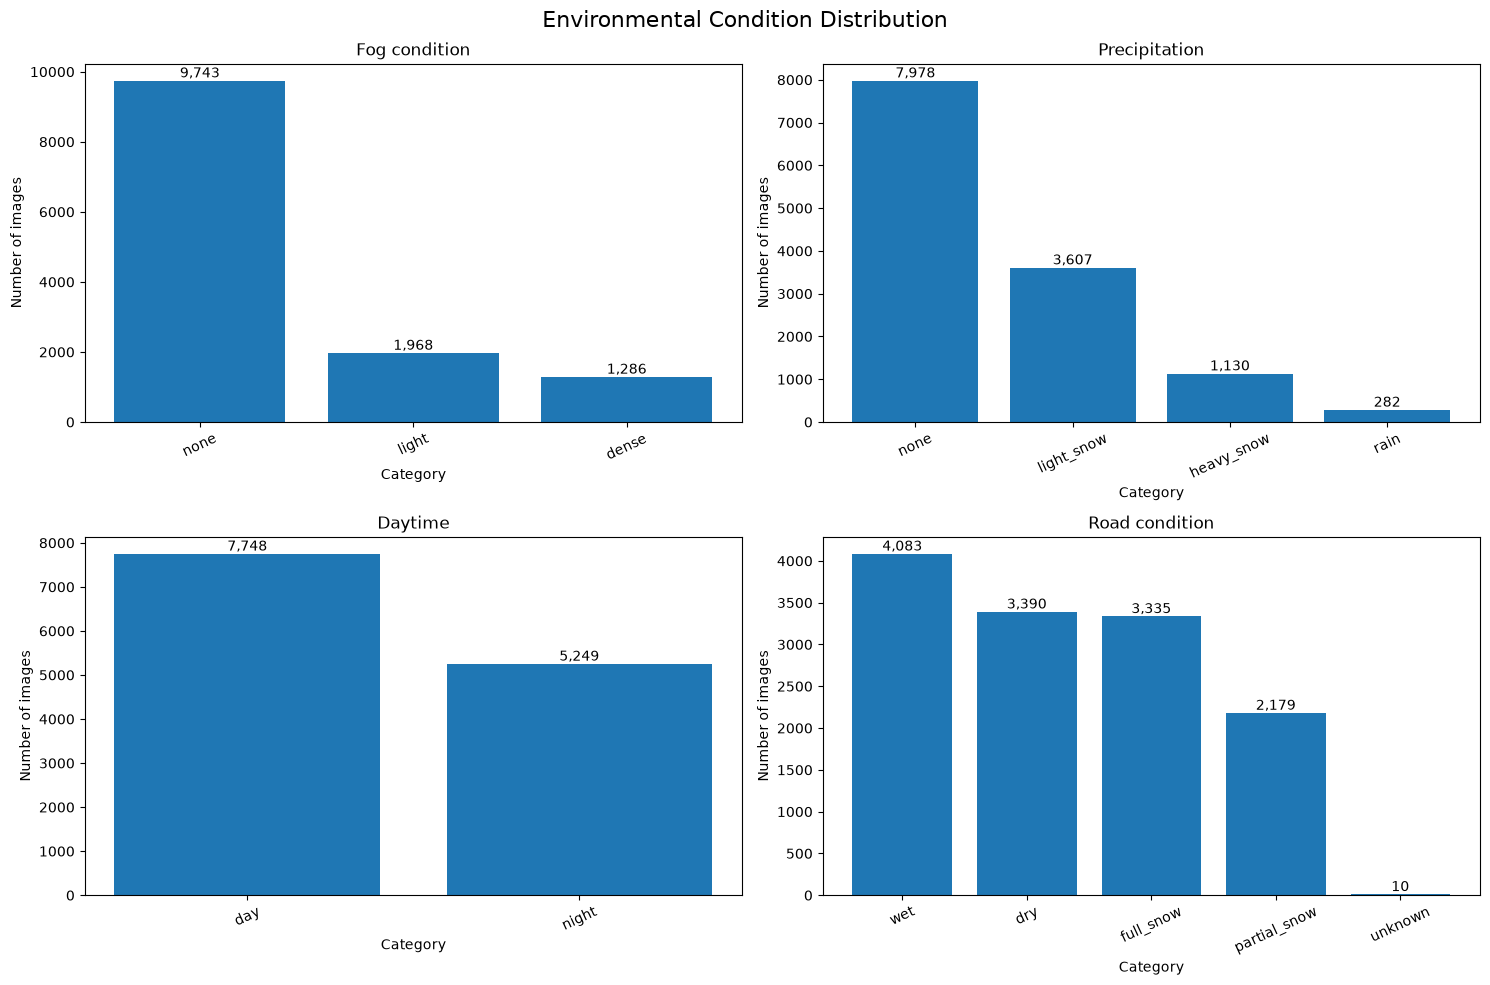

TWILIGHT DISTRIBUTION


twilight
False    10869
True      2128
Name: count, dtype: Int64

In [ ]:
# 2.27 — Environmental and Illumination Distribution Analysis

import matplotlib.pyplot as plt

# Define environmental categories
distribution_columns = {
    "Fog condition": "fog_condition",
    "Precipitation": "precipitation_condition",
    "Daytime": "daytime_condition",
    "Road condition": "road_condition"
}

# Create one subplot per environmental dimension
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(15, 10)
)

axes = axes.flatten()

for ax, (title, column) in zip(
    axes,
    distribution_columns.items()
):

    counts = master_df[column].value_counts()

    ax.bar(
        counts.index.astype(str),
        counts.values
    )

    ax.set_title(title)
    ax.set_xlabel("Category")
    ax.set_ylabel("Number of images")
    ax.tick_params(axis="x", rotation=25)

    # Add counts above each bar
    for index, value in enumerate(counts.values):
        ax.text(
            index,
            value,
            f"{value:,}",
            ha="center",
            va="bottom"
        )

plt.suptitle(
    "Environmental Condition Distribution",
    fontsize=16
)

plt.tight_layout()
plt.show()


# Independent twilight distribution
twilight_counts = (
    master_df["twilight"]
    .value_counts(dropna=False)
    .sort_index()
)

print("TWILIGHT DISTRIBUTION")
display(twilight_counts)


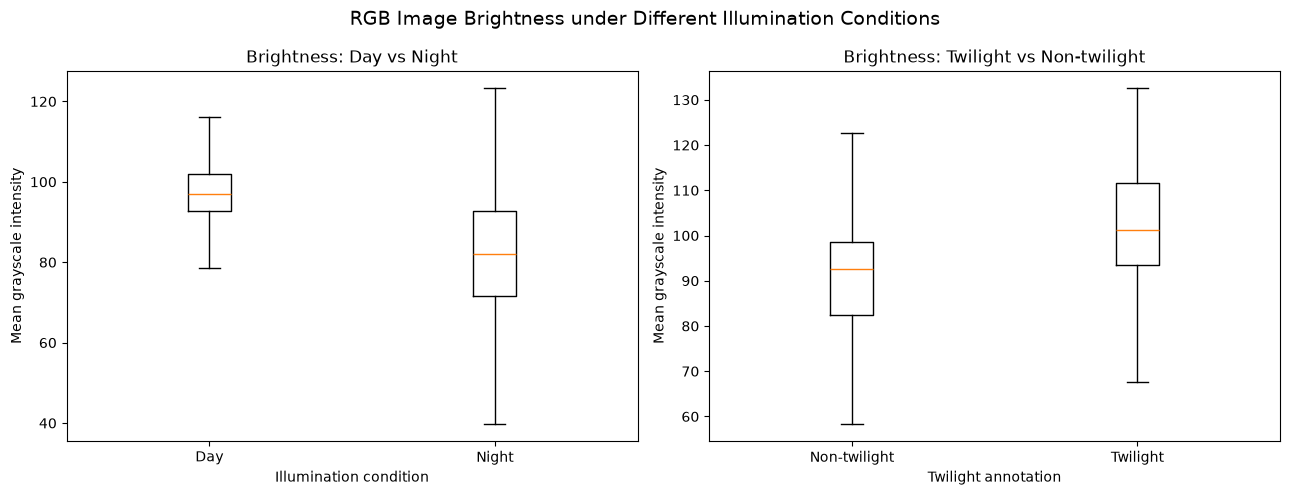

BRIGHTNESS STATISTICS BY DAYTIME


,count,mean,median,std
daytime_condition,,,,
day,7748,99.322413,96.899626,10.398368
night,5249,81.342653,82.062926,17.284384



BRIGHTNESS STATISTICS BY TWILIGHT


,count,mean,median,std
twilight,,,,
False,10869,90.097935,92.695208,16.341870
True,2128,102.087964,101.264299,11.031511


In [46]:
# 2.28 — Brightness Analysis by Illumination

import matplotlib.pyplot as plt

# Prepare data groups
day_groups = [
    master_df.loc[
        master_df["daytime_condition"] == "day",
        "brightness_mean"
    ].dropna(),

    master_df.loc[
        master_df["daytime_condition"] == "night",
        "brightness_mean"
    ].dropna()
]

twilight_groups = [
    master_df.loc[
        master_df["twilight"] == False,
        "brightness_mean"
    ].dropna(),

    master_df.loc[
        master_df["twilight"] == True,
        "brightness_mean"
    ].dropna()
]

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Brightness: Day vs Night
axes[0].boxplot(
    day_groups,
    tick_labels=["Day", "Night"],
    showfliers=False
)

axes[0].set_title("Brightness: Day vs Night")
axes[0].set_ylabel("Mean grayscale intensity")
axes[0].set_xlabel("Illumination condition")

# Brightness: Twilight vs Non-twilight
axes[1].boxplot(
    twilight_groups,
    tick_labels=["Non-twilight", "Twilight"],
    showfliers=False
)

axes[1].set_title("Brightness: Twilight vs Non-twilight")
axes[1].set_ylabel("Mean grayscale intensity")
axes[1].set_xlabel("Twilight annotation")

plt.suptitle(
    "RGB Image Brightness under Different Illumination Conditions",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Numerical summary
print("BRIGHTNESS STATISTICS BY DAYTIME")
display(
    master_df.groupby("daytime_condition")["brightness_mean"]
    .agg(["count", "mean", "median", "std"])
)

print("\nBRIGHTNESS STATISTICS BY TWILIGHT")
display(
    master_df.groupby("twilight")["brightness_mean"]
    .agg(["count", "mean", "median", "std"])
)

DAYTIME AND TWILIGHT COMBINATIONS


twilight,False,True,All
daytime_condition,,,
day,6412,1336,7748
night,4457,792,5249
All,10869,2128,12997



BRIGHTNESS BY DAYTIME AND TWILIGHT


count    mean  median    std
daytime_condition twilight                              
day               False      6412   98.69   96.82  10.07
                  True       1336  102.33   97.70  11.38
night             False      4457   77.73   79.36  15.69
                  True        792  101.67  103.12  10.41

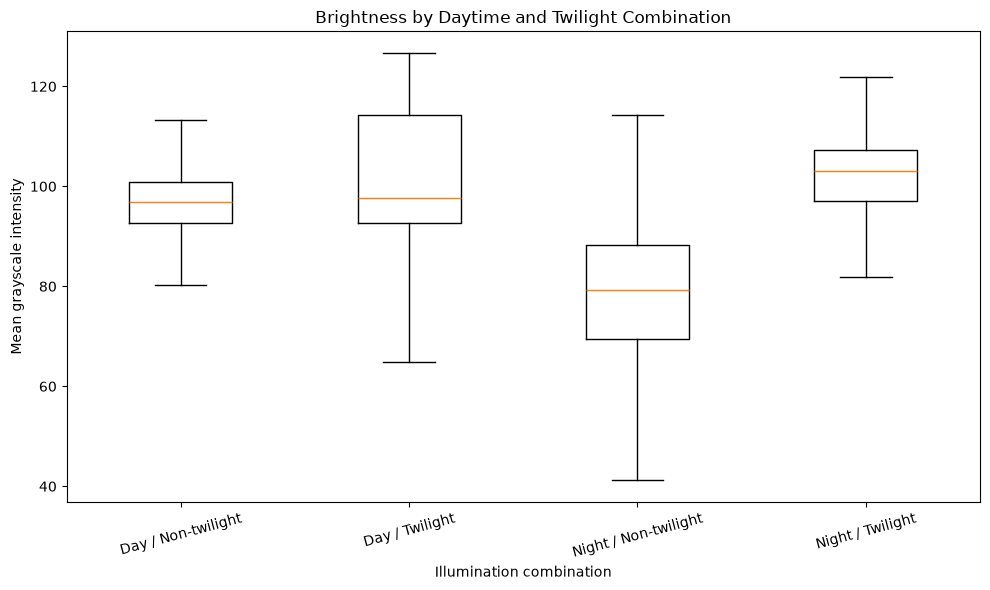

In [47]:
# 2.29 — Analyze Daytime and Twilight Combinations

# Cross-tabulation of daytime and twilight annotations
illumination_combinations = pd.crosstab(
    master_df["daytime_condition"],
    master_df["twilight"],
    margins=True
)

print("DAYTIME AND TWILIGHT COMBINATIONS")
print("=" * 60)

display(illumination_combinations)


# Calculate brightness statistics for each combination
brightness_by_illumination = (
    master_df.groupby(
        ["daytime_condition", "twilight"]
    )["brightness_mean"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("\nBRIGHTNESS BY DAYTIME AND TWILIGHT")
print("=" * 60)

display(brightness_by_illumination)


# Visualize brightness for all combinations
illumination_groups = [
    master_df.loc[
        (master_df["daytime_condition"] == daytime) &
        (master_df["twilight"] == twilight),
        "brightness_mean"
    ].dropna()
    for daytime, twilight in [
        ("day", False),
        ("day", True),
        ("night", False),
        ("night", True)
    ]
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    illumination_groups,
    tick_labels=[
        "Day / Non-twilight",
        "Day / Twilight",
        "Night / Non-twilight",
        "Night / Twilight"
    ],
    showfliers=False
)

ax.set_title("Brightness by Daytime and Twilight Combination")
ax.set_ylabel("Mean grayscale intensity")
ax.set_xlabel("Illumination combination")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

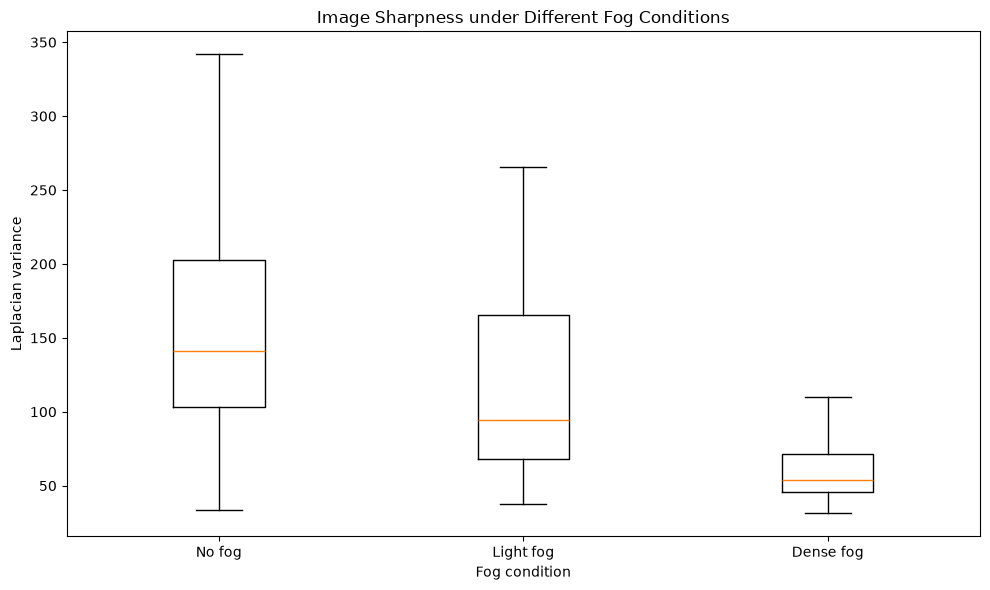

SHARPNESS STATISTICS BY FOG CONDITION


,count,mean,median,std
fog_condition,,,,
none,9743,151.61,141.37,56.29
light,1968,115.17,94.76,54.99
dense,1286,75.28,54.13,50.63


In [48]:
# 2.30 — Sharpness Analysis by Fog Condition

# Define fog categories in the desired order
fog_categories = ["none", "light", "dense"]

# Prepare sharpness data
sharpness_groups = [
    master_df.loc[
        master_df["fog_condition"] == category,
        "sharpness_laplacian_var"
    ].dropna()
    for category in fog_categories
]

# Create boxplot
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    sharpness_groups,
    tick_labels=["No fog", "Light fog", "Dense fog"],
    showfliers=False
)

ax.set_title("Image Sharpness under Different Fog Conditions")
ax.set_xlabel("Fog condition")
ax.set_ylabel("Laplacian variance")

plt.tight_layout()
plt.show()

# Calculate descriptive statistics
sharpness_by_fog = (
    master_df.groupby("fog_condition")["sharpness_laplacian_var"]
    .agg(["count", "mean", "median", "std"])
    .reindex(fog_categories)
    .round(2)
)

print("SHARPNESS STATISTICS BY FOG CONDITION")
print("=" * 65)

display(sharpness_by_fog)

In [51]:
# 2.31 — Statistical Significance of Sharpness Differences

from scipy.stats import kruskal

# Prepare groups
no_fog = master_df.loc[
    master_df["fog_condition"] == "none",
    "sharpness_laplacian_var"
].dropna()

light_fog = master_df.loc[
    master_df["fog_condition"] == "light",
    "sharpness_laplacian_var"
].dropna()

dense_fog = master_df.loc[
    master_df["fog_condition"] == "dense",
    "sharpness_laplacian_var"
].dropna()

# Kruskal-Wallis test
statistic, p_value = kruskal(
    no_fog,
    light_fog,
    dense_fog
)

print("KRUSKAL-WALLIS TEST")
print("=" * 55)

print(f"H-statistic: {statistic:.4f}")
print(f"P-value: {p_value:.6e}")

alpha = 0.05

if p_value < alpha:
    print("\nResult: Statistically significant differences detected.")
else:
    print("\nResult: No statistically significant differences detected.")

# 2.32 — Dunn's Post-hoc Test with Holm Correction

import numpy as np
import pandas as pd

from itertools import combinations
from scipy.stats import rankdata, norm

# Prepare data
data = master_df[
    ["fog_condition", "sharpness_laplacian_var"]
].dropna()

# Calculate pooled ranks
data = data.copy()
data["rank"] = rankdata(data["sharpness_laplacian_var"])

# Group statistics
group_stats = data.groupby("fog_condition").agg(
    count=("rank", "count"),
    mean_rank=("rank", "mean")
)

N = len(data)

# Tie correction
tie_counts = data["sharpness_laplacian_var"].value_counts()
tie_sum = sum(t**3 - t for t in tie_counts)

tie_correction = 1 - tie_sum / (N**3 - N)

# Dunn pairwise comparisons
comparisons = []

for group_a, group_b in combinations(
    ["none", "light", "dense"], 2
):
    n_a = group_stats.loc[group_a, "count"]
    n_b = group_stats.loc[group_b, "count"]

    rank_a = group_stats.loc[group_a, "mean_rank"]
    rank_b = group_stats.loc[group_b, "mean_rank"]

    variance = (
        N * (N + 1) / 12
    ) * tie_correction

    standard_error = np.sqrt(
        variance * (1 / n_a + 1 / n_b)
    )

    z_score = (rank_a - rank_b) / standard_error

    p_value = 2 * norm.sf(abs(z_score))

    comparisons.append({
        "comparison": f"{group_a} vs {group_b}",
        "z_score": z_score,
        "p_raw": p_value
    })

# Apply Holm correction
results = pd.DataFrame(comparisons)

order = np.argsort(results["p_raw"].values)
adjusted = np.empty(len(results))

running_max = 0

for rank, index in enumerate(order):
    adjusted_p = (
        len(results) - rank
    ) * results.loc[index, "p_raw"]

    running_max = max(running_max, adjusted_p)

    adjusted[index] = min(running_max, 1.0)

results["p_holm"] = adjusted

results["significant"] = results["p_holm"] < 0.05

print("DUNN POST-HOC TEST WITH HOLM CORRECTION")
print("=" * 65)

display(results.round(6))

KRUSKAL-WALLIS TEST
H-statistic: 2432.2982
P-value: 0.000000e+00

Result: Statistically significant differences detected.
DUNN POST-HOC TEST WITH HOLM CORRECTION


,comparison,z_score,p_raw,p_holm,significant
0,none vs light,25.738802,0.0,0.0,True
1,none vs dense,45.257868,0.0,0.0,True
2,light vs dense,19.707341,0.0,0.0,True


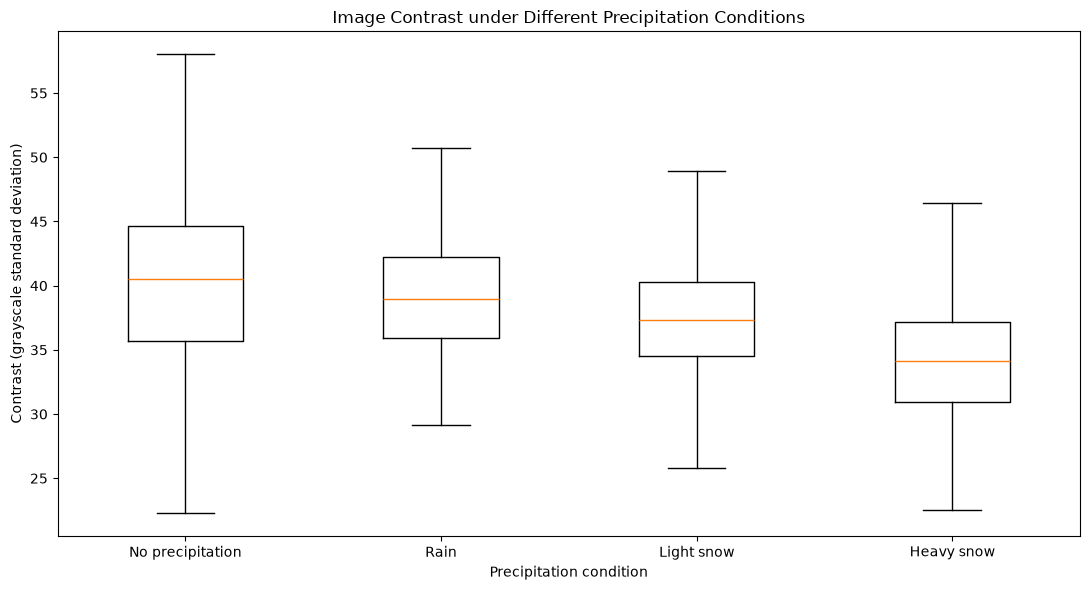

CONTRAST STATISTICS BY PRECIPITATION CONDITION


,count,mean,median,std
precipitation_condition,,,,
none,7978,40.39,40.53,6.84
rain,282,38.31,38.97,5.87
light_snow,3607,37.48,37.29,4.48
heavy_snow,1130,34.10,34.14,4.55


In [52]:
# 2.33 — Contrast Analysis by Precipitation Condition

import matplotlib.pyplot as plt

# Define precipitation categories
precipitation_categories = [
    "none",
    "rain",
    "light_snow",
    "heavy_snow"
]

# Prepare contrast data for each category
contrast_groups = [
    master_df.loc[
        master_df["precipitation_condition"] == category,
        "contrast_std"
    ].dropna()
    for category in precipitation_categories
]

# Create boxplot
fig, ax = plt.subplots(figsize=(11, 6))

ax.boxplot(
    contrast_groups,
    tick_labels=[
        "No precipitation",
        "Rain",
        "Light snow",
        "Heavy snow"
    ],
    showfliers=False
)

ax.set_title("Image Contrast under Different Precipitation Conditions")
ax.set_xlabel("Precipitation condition")
ax.set_ylabel("Contrast (grayscale standard deviation)")

plt.tight_layout()
plt.show()


# Calculate descriptive statistics
contrast_by_precipitation = (
    master_df.groupby("precipitation_condition")["contrast_std"]
    .agg(["count", "mean", "median", "std"])
    .reindex(precipitation_categories)
    .round(2)
)

print("CONTRAST STATISTICS BY PRECIPITATION CONDITION")
print("=" * 70)

display(contrast_by_precipitation)

In [53]:
# 2.34 — Statistical Analysis of Contrast Differences

from scipy.stats import kruskal

# Prepare precipitation groups
no_precipitation = master_df.loc[
    master_df["precipitation_condition"] == "none",
    "contrast_std"
].dropna()

rain = master_df.loc[
    master_df["precipitation_condition"] == "rain",
    "contrast_std"
].dropna()

light_snow = master_df.loc[
    master_df["precipitation_condition"] == "light_snow",
    "contrast_std"
].dropna()

heavy_snow = master_df.loc[
    master_df["precipitation_condition"] == "heavy_snow",
    "contrast_std"
].dropna()

# Kruskal-Wallis test
statistic, p_value = kruskal(
    no_precipitation,
    rain,
    light_snow,
    heavy_snow
)

print("KRUSKAL-WALLIS TEST — IMAGE CONTRAST")
print("=" * 65)

print(f"H-statistic: {statistic:.4f}")
print(f"P-value: {p_value:.6e}")

if p_value < 0.05:
    print("\nResult: Statistically significant differences detected.")
else:
    print("\nResult: No statistically significant differences detected.")

KRUSKAL-WALLIS TEST — IMAGE CONTRAST
H-statistic: 1337.7500
P-value: 9.478488e-290

Result: Statistically significant differences detected.


In [54]:
# 2.35 — Dunn Post-hoc Test with Holm Correction
# Contrast differences across precipitation conditions

import numpy as np
import pandas as pd

from itertools import combinations
from scipy.stats import rankdata, norm

# Prepare data
data = master_df[
    ["precipitation_condition", "contrast_std"]
].dropna().copy()

precipitation_categories = [
    "none",
    "rain",
    "light_snow",
    "heavy_snow"
]

# Calculate pooled ranks
data["rank"] = rankdata(data["contrast_std"])

# Group statistics
group_stats = data.groupby("precipitation_condition").agg(
    count=("rank", "count"),
    mean_rank=("rank", "mean")
)

N = len(data)

# Calculate tie correction
tie_counts = data["contrast_std"].value_counts()

tie_sum = sum(
    t**3 - t for t in tie_counts
)

tie_correction = 1 - tie_sum / (N**3 - N)

# Dunn pairwise comparisons
comparisons = []

for group_a, group_b in combinations(
    precipitation_categories, 2
):
    n_a = group_stats.loc[group_a, "count"]
    n_b = group_stats.loc[group_b, "count"]

    rank_a = group_stats.loc[group_a, "mean_rank"]
    rank_b = group_stats.loc[group_b, "mean_rank"]

    variance = (
        N * (N + 1) / 12
    ) * tie_correction

    standard_error = np.sqrt(
        variance * (1 / n_a + 1 / n_b)
    )

    z_score = (rank_a - rank_b) / standard_error

    p_value = 2 * norm.sf(abs(z_score))

    comparisons.append({
        "comparison": f"{group_a} vs {group_b}",
        "z_score": z_score,
        "p_raw": p_value
    })

# Apply Holm correction
results = pd.DataFrame(comparisons)

order = np.argsort(results["p_raw"].values)
adjusted = np.empty(len(results))

running_max = 0

for rank, index in enumerate(order):
    adjusted_p = (
        len(results) - rank
    ) * results.loc[index, "p_raw"]

    running_max = max(running_max, adjusted_p)

    adjusted[index] = min(running_max, 1.0)

results["p_holm"] = adjusted
results["significant"] = results["p_holm"] < 0.05

print("DUNN POST-HOC TEST — CONTRAST")
print("=" * 70)

display(results.round(8))

DUNN POST-HOC TEST — CONTRAST


,comparison,z_score,p_raw,p_holm,significant
0,none vs rain,3.788438,0.000152,0.000236,True
1,none vs light_snow,23.305963,0.000000,0.000000,True
2,none vs heavy_snow,32.218944,0.000000,0.000000,True
3,rain vs light_snow,3.850222,0.000118,0.000236,True
4,rain vs heavy_snow,11.936027,0.000000,0.000000,True
5,light_snow vs heavy_snow,16.322922,0.000000,0.000000,True


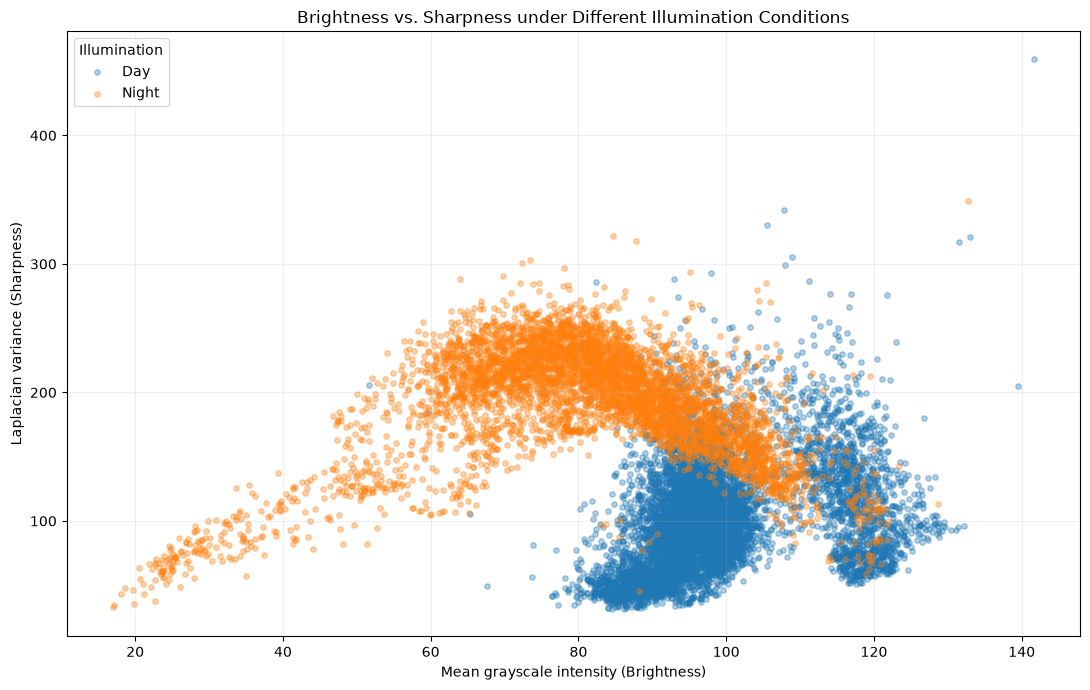

In [55]:
# 2.36 — Brightness vs. Sharpness by Illumination

import matplotlib.pyplot as plt

# Define illumination categories
illumination_categories = ["day", "night"]

# Create figure
fig, ax = plt.subplots(figsize=(11, 7))

# Plot each illumination category
for category in illumination_categories:

    subset = master_df[
        master_df["daytime_condition"] == category
    ]

    ax.scatter(
        subset["brightness_mean"],
        subset["sharpness_laplacian_var"],
        label=category.capitalize(),
        alpha=0.35,
        s=15
    )

# Configure plot
ax.set_title(
    "Brightness vs. Sharpness under Different Illumination Conditions"
)

ax.set_xlabel("Mean grayscale intensity (Brightness)")
ax.set_ylabel("Laplacian variance (Sharpness)")

ax.legend(title="Illumination")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [56]:
# 2.37 — Brightness and Sharpness Correlation Analysis

from scipy.stats import pearsonr, spearmanr

illumination_categories = ["day", "night"]

correlation_results = []

for category in illumination_categories:

    subset = master_df[
        master_df["daytime_condition"] == category
    ][
        ["brightness_mean", "sharpness_laplacian_var"]
    ].dropna()

    # Pearson correlation
    pearson_corr, pearson_p = pearsonr(
        subset["brightness_mean"],
        subset["sharpness_laplacian_var"]
    )

    # Spearman correlation
    spearman_corr, spearman_p = spearmanr(
        subset["brightness_mean"],
        subset["sharpness_laplacian_var"]
    )

    correlation_results.append({
        "illumination": category,
        "count": len(subset),
        "pearson_r": pearson_corr,
        "pearson_p": pearson_p,
        "spearman_r": spearman_corr,
        "spearman_p": spearman_p
    })

correlation_df = pd.DataFrame(correlation_results)

print("BRIGHTNESS vs. SHARPNESS CORRELATION")
print("=" * 70)

display(correlation_df.round(6))

BRIGHTNESS vs. SHARPNESS CORRELATION


,illumination,count,pearson_r,pearson_p,spearman_r,spearman_p
0,day,7748,0.303819,0.000000,0.372520,0.0
1,night,5249,-0.001461,0.915714,-0.279007,0.0


FOG × PRECIPITATION — IMAGE COUNTS


precipitation_condition,none,rain,light_snow,heavy_snow
fog_condition,,,,
none,6618,282,2658,185
light,263,0,904,801
dense,1097,0,45,144



FOG × PRECIPITATION — DATASET PERCENTAGES (%)


precipitation_condition,none,rain,light_snow,heavy_snow
fog_condition,,,,
none,50.92,2.17,20.45,1.42
light,2.02,0.00,6.96,6.16
dense,8.44,0.00,0.35,1.11


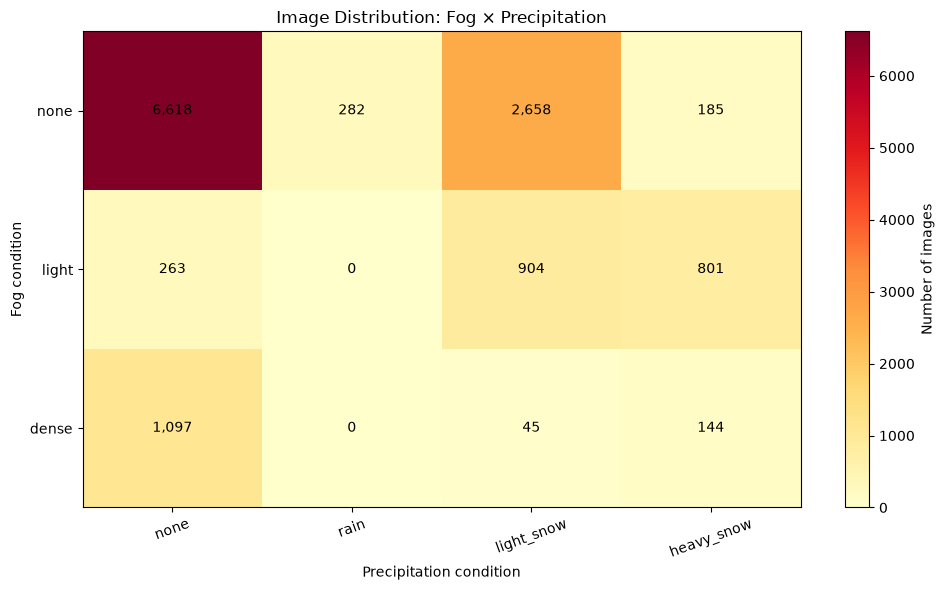

In [57]:
# 2.39 — Environmental Combination Frequency Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Define category order
fog_categories = ["none", "light", "dense"]

precipitation_categories = [
    "none",
    "rain",
    "light_snow",
    "heavy_snow"
]

# Create frequency table
combination_counts = pd.crosstab(
    master_df["fog_condition"],
    master_df["precipitation_condition"]
)

# Ensure all categories are represented
combination_counts = combination_counts.reindex(
    index=fog_categories,
    columns=precipitation_categories,
    fill_value=0
)

print("FOG × PRECIPITATION — IMAGE COUNTS")
print("=" * 70)

display(combination_counts)


# Calculate percentages relative to the complete dataset
combination_percentages = (
    combination_counts / len(master_df) * 100
).round(2)

print("\nFOG × PRECIPITATION — DATASET PERCENTAGES (%)")
print("=" * 70)

display(combination_percentages)


# Visualize combinations using a heatmap
fig, ax = plt.subplots(figsize=(10, 6))

image = ax.imshow(
    combination_counts.values,
    cmap="YlOrRd",
    aspect="auto"
)

ax.set_xticks(range(len(precipitation_categories)))
ax.set_xticklabels(precipitation_categories, rotation=20)

ax.set_yticks(range(len(fog_categories)))
ax.set_yticklabels(fog_categories)

ax.set_xlabel("Precipitation condition")
ax.set_ylabel("Fog condition")
ax.set_title("Image Distribution: Fog × Precipitation")

# Add image counts to each cell
for i in range(len(fog_categories)):
    for j in range(len(precipitation_categories)):

        count = combination_counts.iloc[i, j]

        ax.text(
            j,
            i,
            f"{count:,}",
            ha="center",
            va="center",
            color="black"
        )

plt.colorbar(image, ax=ax, label="Number of images")

plt.tight_layout()
plt.show()

In [58]:
# 2.40 — Image Quality Analysis by Fog and Precipitation

# Calculate image quality statistics for each combination
quality_by_environment = (
    master_df
    .groupby(
        ["fog_condition", "precipitation_condition"]
    )
    .agg(
        image_count=("image_name", "count"),

        brightness_mean=("brightness_mean", "mean"),
        brightness_median=("brightness_mean", "median"),

        contrast_mean=("contrast_std", "mean"),
        contrast_median=("contrast_std", "median"),

        sharpness_mean=("sharpness_laplacian_var", "mean"),
        sharpness_median=("sharpness_laplacian_var", "median")
    )
    .round(2)
    .reset_index()
)

# Sort by fog and precipitation categories
fog_order = ["none", "light", "dense"]

precipitation_order = [
    "none",
    "rain",
    "light_snow",
    "heavy_snow"
]

quality_by_environment["fog_condition"] = pd.Categorical(
    quality_by_environment["fog_condition"],
    categories=fog_order,
    ordered=True
)

quality_by_environment["precipitation_condition"] = pd.Categorical(
    quality_by_environment["precipitation_condition"],
    categories=precipitation_order,
    ordered=True
)

quality_by_environment = quality_by_environment.sort_values(
    ["fog_condition", "precipitation_condition"]
)

print("IMAGE QUALITY BY FOG × PRECIPITATION")
print("=" * 80)

display(quality_by_environment)

IMAGE QUALITY BY FOG × PRECIPITATION


,fog_condition,precipitation_condition,image_count,brightness_mean,brightness_median,contrast_mean,contrast_median,sharpness_mean,sharpness_median
8,none,none,6618,89.77,93.61,41.94,41.79,154.63,143.69
9,none,rain,282,83.57,83.64,38.31,38.97,172.47,198.82
7,none,light_snow,2658,95.52,95.82,38.28,38.21,144.92,137.55
6,none,heavy_snow,185,97.65,98.78,37.19,37.20,108.02,86.59
5,light,none,263,93.34,90.12,35.99,35.90,110.66,86.50
4,light,light_snow,904,95.97,96.41,35.48,35.64,134.96,147.13
3,light,heavy_snow,801,97.33,97.21,34.15,34.14,94.33,75.88
2,dense,none,1097,90.11,87.64,32.08,31.84,75.44,54.51
1,dense,light_snow,45,105.37,109.00,30.74,30.60,73.94,59.76
0,dense,heavy_snow,144,97.38,94.92,29.85,29.05,74.50,50.84


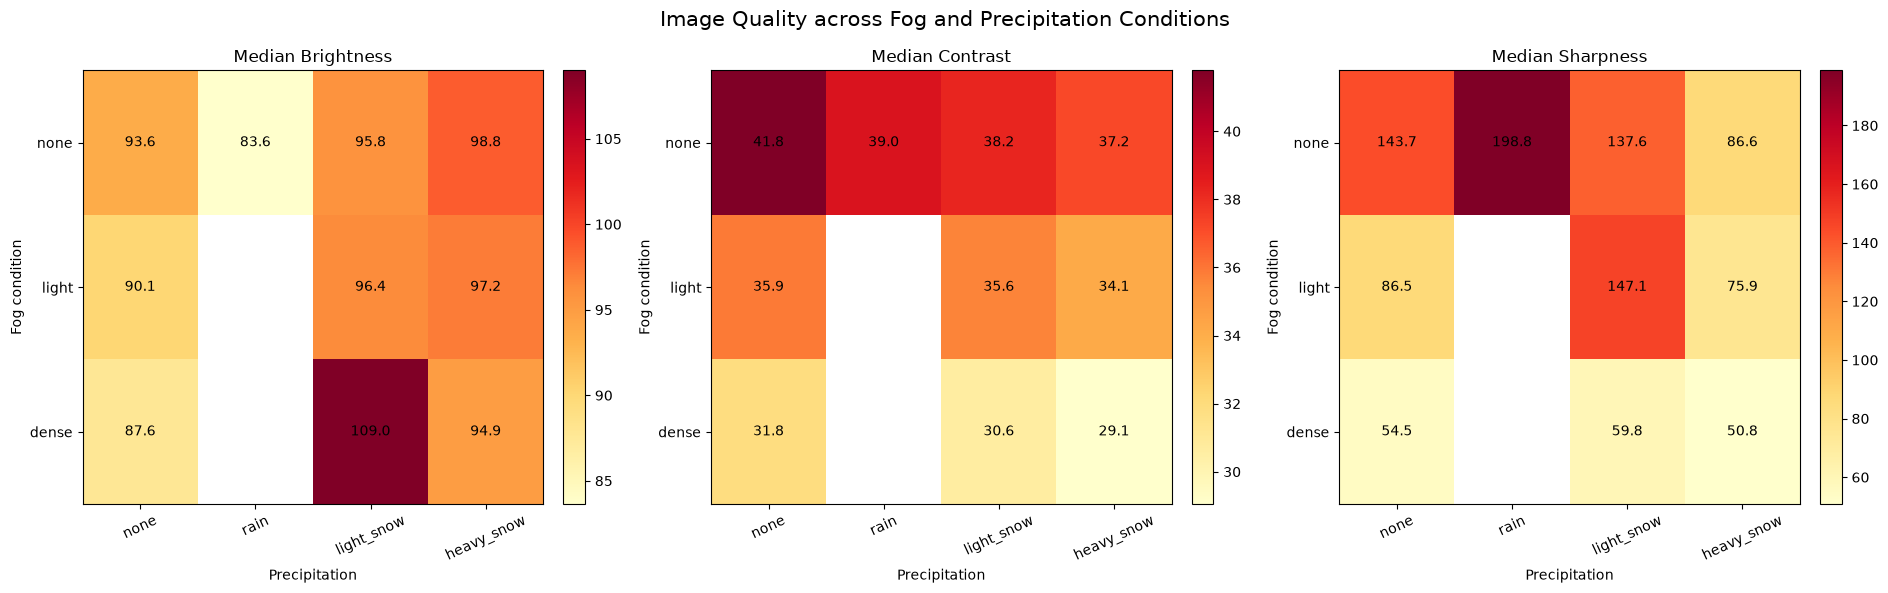

In [60]:
# 2.41 — Environmental Image Quality Heatmaps
# Using Matplotlib only

import matplotlib.pyplot as plt
import numpy as np

# Define category order
fog_order = ["none", "light", "dense"]

precipitation_order = [
    "none",
    "rain",
    "light_snow",
    "heavy_snow"
]

# Metrics to visualize
metrics = {
    "brightness_median": "Median Brightness",
    "contrast_median": "Median Contrast",
    "sharpness_median": "Median Sharpness"
}

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (metric, title) in zip(axes, metrics.items()):

    # Create matrix
    matrix = quality_by_environment.pivot(
        index="fog_condition",
        columns="precipitation_condition",
        values=metric
    )

    matrix = matrix.reindex(
        index=fog_order,
        columns=precipitation_order
    )

    values = matrix.to_numpy(dtype=float)

    # Plot heatmap
    image = ax.imshow(
        values,
        cmap="YlOrRd",
        aspect="auto"
    )

    # Configure axes
    ax.set_xticks(range(len(precipitation_order)))
    ax.set_xticklabels(precipitation_order, rotation=25)

    ax.set_yticks(range(len(fog_order)))
    ax.set_yticklabels(fog_order)

    ax.set_title(title)
    ax.set_xlabel("Precipitation")
    ax.set_ylabel("Fog condition")

    # Add values to cells
    for i in range(len(fog_order)):
        for j in range(len(precipitation_order)):

            value = values[i, j]

            if not np.isnan(value):
                ax.text(
                    j,
                    i,
                    f"{value:.1f}",
                    ha="center",
                    va="center",
                    color="black"
                )

    # Individual color scale
    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

plt.suptitle(
    "Image Quality across Fog and Precipitation Conditions",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [61]:
# 2.43 — Calculate Relative Image Quality Variations

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define reference condition
reference = quality_by_environment[
    (quality_by_environment["fog_condition"] == "none") &
    (quality_by_environment["precipitation_condition"] == "none")
].iloc[0]

# Define metrics and reference values
metrics = {
    "brightness_median": reference["brightness_median"],
    "contrast_median": reference["contrast_median"],
    "sharpness_median": reference["sharpness_median"]
}

# Copy original environmental quality table
relative_quality = quality_by_environment.copy()

# Calculate percentage variation for each metric
for metric, reference_value in metrics.items():

    relative_column = metric.replace("_median", "_variation_pct")

    relative_quality[relative_column] = (
        (relative_quality[metric] - reference_value)
        / reference_value
    ) * 100

# Round results
variation_columns = [
    "brightness_variation_pct",
    "contrast_variation_pct",
    "sharpness_variation_pct"
]

relative_quality[variation_columns] = (
    relative_quality[variation_columns].round(2)
)

# Display results
print("RELATIVE IMAGE QUALITY VARIATION")
print("=" * 75)

display(
    relative_quality[
        [
            "fog_condition",
            "precipitation_condition",
            "image_count",
            *variation_columns
        ]
    ]
)

RELATIVE IMAGE QUALITY VARIATION


,fog_condition,precipitation_condition,image_count,brightness_variation_pct,contrast_variation_pct,sharpness_variation_pct
8,none,none,6618,0.00,0.00,0.00
9,none,rain,282,-10.65,-6.75,38.37
7,none,light_snow,2658,2.36,-8.57,-4.27
6,none,heavy_snow,185,5.52,-10.98,-39.74
5,light,none,263,-3.73,-14.09,-39.80
4,light,light_snow,904,2.99,-14.72,2.39
3,light,heavy_snow,801,3.85,-18.31,-47.19
2,dense,none,1097,-6.38,-23.81,-62.06
1,dense,light_snow,45,16.44,-26.78,-58.41
0,dense,heavy_snow,144,1.40,-30.49,-64.62


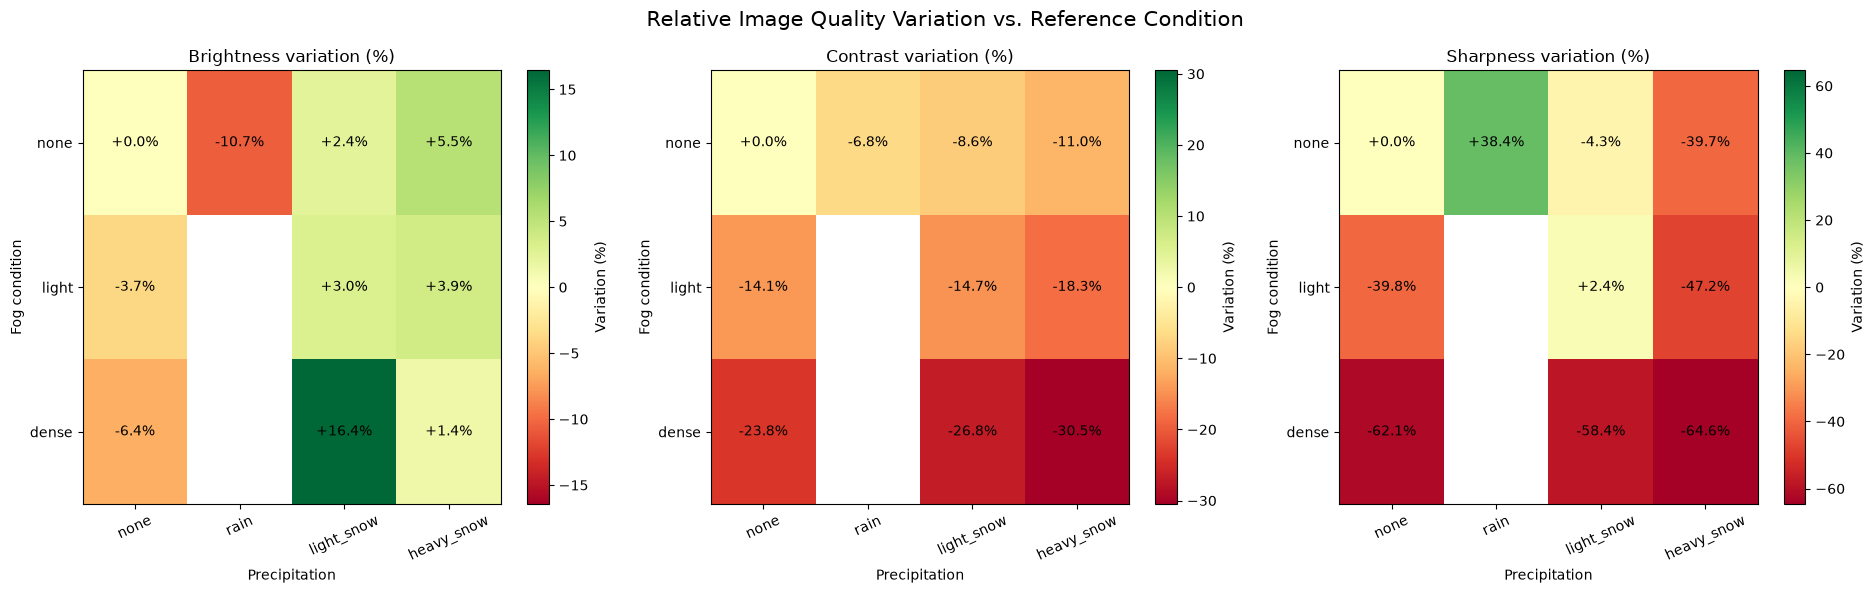

In [62]:
# 2.44 — Relative Image Quality Variation Heatmaps

from matplotlib.colors import TwoSlopeNorm

fog_order = ["none", "light", "dense"]

precipitation_order = [
    "none",
    "rain",
    "light_snow",
    "heavy_snow"
]

variation_metrics = {
    "brightness_variation_pct": "Brightness variation (%)",
    "contrast_variation_pct": "Contrast variation (%)",
    "sharpness_variation_pct": "Sharpness variation (%)"
}

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (metric, title) in zip(
    axes,
    variation_metrics.items()
):

    matrix = relative_quality.pivot(
        index="fog_condition",
        columns="precipitation_condition",
        values=metric
    ).reindex(
        index=fog_order,
        columns=precipitation_order
    )

    values = matrix.to_numpy(dtype=float)

    # Symmetric color scale around zero
    finite_values = values[np.isfinite(values)]

    limit = max(abs(finite_values.min()), abs(finite_values.max()))

    image = ax.imshow(
        values,
        cmap="RdYlGn",
        norm=TwoSlopeNorm(
            vmin=-limit,
            vcenter=0,
            vmax=limit
        ),
        aspect="auto"
    )

    ax.set_xticks(range(len(precipitation_order)))
    ax.set_xticklabels(precipitation_order, rotation=25)

    ax.set_yticks(range(len(fog_order)))
    ax.set_yticklabels(fog_order)

    ax.set_title(title)
    ax.set_xlabel("Precipitation")
    ax.set_ylabel("Fog condition")

    for i in range(len(fog_order)):
        for j in range(len(precipitation_order)):

            value = values[i, j]

            if np.isfinite(value):
                ax.text(
                    j,
                    i,
                    f"{value:+.1f}%",
                    ha="center",
                    va="center",
                    color="black"
                )

    fig.colorbar(
        image,
        ax=ax,
        label="Variation (%)"
    )

plt.suptitle(
    "Relative Image Quality Variation vs. Reference Condition",
    fontsize=15
)

plt.tight_layout()
plt.show()